![banner](https://i.imgur.com/a3uAqnb.png)

# Applied Computer Vision — Day 3 Lab (Worked Example)
## Fine-tuning & Advanced Training

**KAUST Academy · Applied Computer Vision (Postgraduate Diploma)**

On Day 2 you trained a CNN **from scratch**. Today you start from a network that has already learned
to see — a model **pretrained** on ImageNet's 1.28 M images, downloaded from the **Hugging Face Hub** —
and **fine-tune** it for your own classes.

> **A worked example.** Every cell runs as-is on a Colab **GPU** runtime. Before running a cell,
> **predict** what it will print or show; then run it and compare.

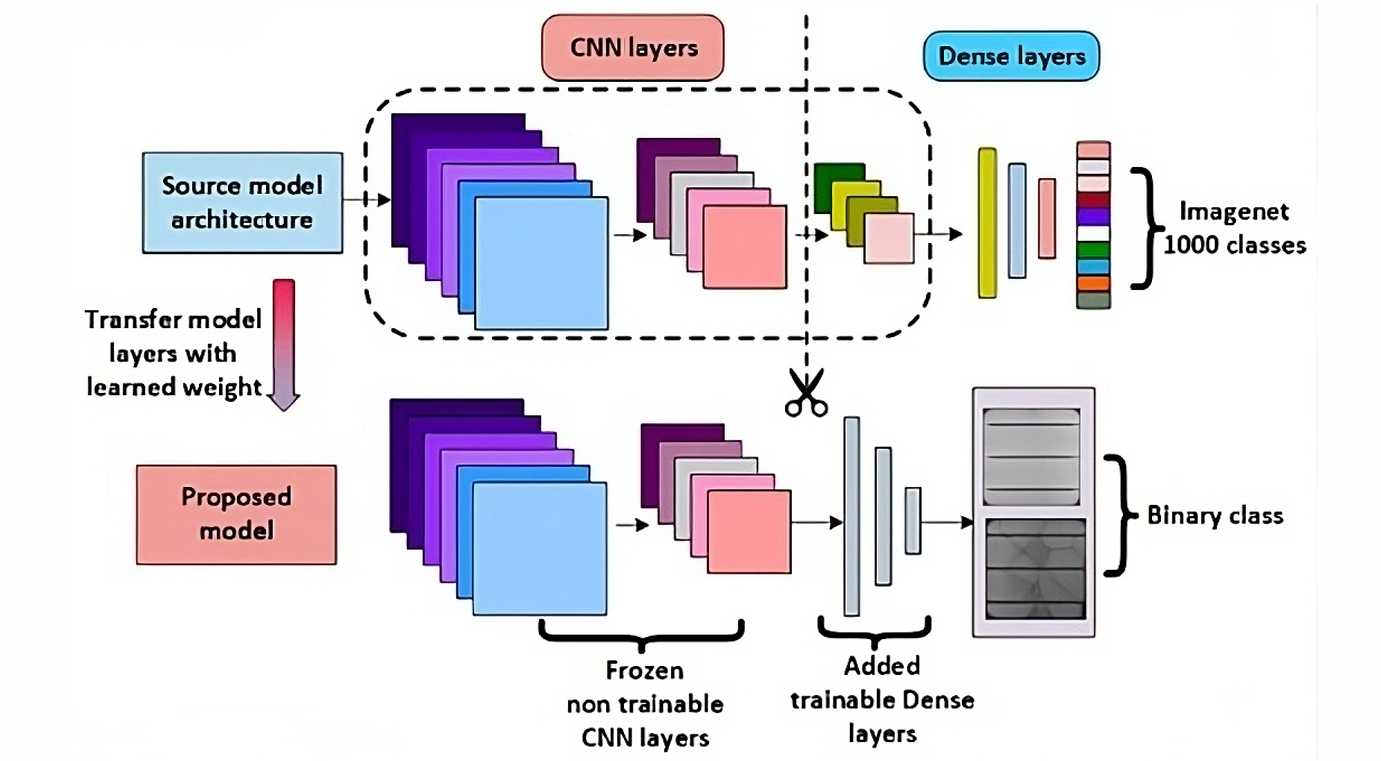

Source: [KAUST Academy Advanced AI program](https://github.com/KAUST-Academy/2025_Advanced-Ai/blob/main/Slides/computer_vision_day_2.pdf)

# The Big Picture of Transfer Learning



- Instead of always training from scratch and collecting huge amounts! **Tune** a pretrained model to your task with very few data samples!

## The flow of the lab:

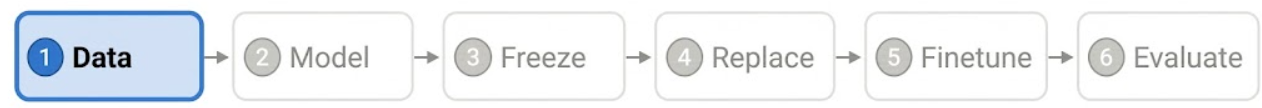

| # | Block | Responsible for | In PyTorch | Built in |
| --- | --- | --- | --- | --- |
| 1 | **Data** | Fetching, processing, and batching dataset | `Dataset`, `DataLoader` | §1 |
| 2 | **Model** | Loading the pre-trained architecture | `transformers` / `huggingface` | §2 |
| 3 | **Freeze** | Locking base weights to prevent gradient updates | `param.requires_grad = False` | §3 |
| 4 | **Replace** | Swapping the final layer for target class count | `model.fc = nn.Linear(...)` | §4 |
| 5 | **Finetune** | Training new head (or un-frozen layers) on data | `optimizer.step()` · `loss.backward()` | §5 |
| 6 | **Evaluate** | Measuring performance on unseen test data | `model.eval()` · `torch.inference_mode()` | §6 |

**Learning outcomes.** After this lab you should be able to

(a) load a pretrained model from the Hugging Face Hub, inspect its blocks, replace its classifier and freeze any part of it,

(b) fine-tune with a linear probe or end-to-end, and say when each is the right choice,

(c) explain bias and variance, and predict how the amount of data shifts the balance,

(d) recognise overfitting in learning curves and apply the right mitigation for it,

(e) speed up training with parallel data loading and mixed precision, and know what each knob does,

(f) run a hyperparameter search, track it in Weights & Biases, and read the results critically,

(g) evaluate on a held-out test set with confidence intervals, and save / reload the best model.

---
## 0. Setup

In [1]:
import sys, platform
print("Python:", sys.version.split()[0], "|", platform.platform())

Python: 3.13.15 | Linux-6.6.122+-x86_64-with-glibc2.39


In [2]:
# torch, torchvision, scikit-learn, pandas and matplotlib are preinstalled on Colab.
!pip -q install -U transformers wandb
print("installs done")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.6/12.6 MB 190.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 26.1/26.1 MB 105.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.3/60.3 kB 6.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.5/72.5 kB 9.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 140.1/140.1 kB 21.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 206.3/206.3 kB 31.7 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-adk 2.7.1 requires opentelemetry-api<=1.42.1,>=1.39, but you have opentelemetry-api 1.45.1 which is incompatible.
google-adk 2.7.1 requires opentelemetry-sdk<=1.42.1,>=1.39, but you have opentelemetry-sdk 1.45.1 which is incompatible.
installs done


In [3]:
import importlib, os, torch
from packaging.version import Version

REQUIRED = {"torch": "2.3", "torchvision": "0.18", "transformers": "4.40", "wandb": "0.16",
            "sklearn": "1.2", "pandas": "1.5", "matplotlib": "3.5"}
for mod, min_v in REQUIRED.items():
    try:
        v = importlib.import_module(mod).__version__; ok = Version(v.split("+")[0]) >= Version(min_v)
    except Exception:
        v, ok = "missing", False
    print(f"{'✅' if ok else '❌'} {mod:<13} {v:<14} (need >= {min_v})")

if torch.cuda.is_available():
    cc = torch.cuda.get_device_capability()
    print(f"\nGPU: {torch.cuda.get_device_name(0)} | compute capability {cc[0]}.{cc[1]} | "
          f"mixed precision: {'bfloat16' if cc[0] >= 8 else 'float16 + GradScaler'}")
else:
    print("\n❌ No GPU - switch the runtime to GPU (Runtime -> Change runtime type).")
print(f"CPU cores: {os.cpu_count()}")

✅ torch         2.11.0+cu130   (need >= 2.3)
✅ torchvision   0.26.0+cu130   (need >= 0.18)
✅ transformers  5.19.0         (need >= 4.40)
✅ wandb         0.30.0         (need >= 0.16)
✅ sklearn       1.6.1          (need >= 1.2)
✅ pandas        2.2.3          (need >= 1.5)
✅ matplotlib    3.10.0         (need >= 3.5)

GPU: NVIDIA RTX PRO 6000 Blackwell Server Edition | compute capability 12.0 | mixed precision: bfloat16
CPU cores: 48


---
# Part I - Big data: fine-tuning made easy

**Transfer learning.** A network trained on ImageNet has learned general visual features — edges and
colours in its first layers, textures and parts in the middle, object-level patterns at the top
(Yosinski et al., 2014). Those features are useful for almost any image task, so instead of starting from
random weights we **start from the pretrained ones** and adapt:

1. **Replace the last layer.** The pretrained head predicts ImageNet's 1,000 classes; we swap it for a new,
   randomly initialised layer with **our** number of classes.
2. **Choose what trains.** Either only the new head (**linear probe** - the backbone is *frozen*) or the
   whole network (**full fine-tuning**), usually with a small learning rate so the useful features aren't
   destroyed.

Part I does both on plenty of data, with the simplest possible training loop.

## I.1 Inspect & understand the big data (CIFAR10)

**CIFAR10** is a 10-class dataset *easy to
tell apart*

• Total Images: 60,000

• Training Images: 50,000

• Testing Images: 10,000

• Image Size: 32 × 32

• Color Format: RGB

**📚 Read & learn**
- [CIFAR10](https://www.kaggle.com/datasets/abhiit/cifar-10-image-dataset-original) — the big dataset.

In [4]:
#@title settings
import os, time, math, copy, json, random, shutil
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch, torch.nn as nn
from PIL import Image

# ---- data -----------------------------------------------------------------------------------------
DATA_DIR   = "data"

SEED = 42

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
AMP_DTYPE = (torch.bfloat16 if DEVICE == "cpu" or torch.cuda.get_device_capability()[0] >= 8
             else torch.float16)   # bf16 on L4/A100, fp16 on T4

def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

set_seed()
for d in [DATA_DIR, "checkpoints", "models"]:
    os.makedirs(d, exist_ok=True)
print(f"config loaded | device={DEVICE} | AMP dtype={AMP_DTYPE}")

config loaded | device=cuda | AMP dtype=torch.bfloat16


In [5]:
#@title 0.2 · Load CIFAR-10
from datasets import load_dataset   # Hugging Face (pip install datasets); torchvision's `datasets` stays untouched

CLASSES = ['Airplane', 'Automobile', 'Bird', 'Cat', 'Deer',
           'Dog', 'Frog', 'Horse', 'Ship', 'Truck']
NUM_CLASSES = len(CLASSES)

# Raw datasets: no transform, so we inspect exactly what is stored on disk.
cifar     = load_dataset('uoft-cs/cifar10', cache_dir=DATA_DIR)   # fast HF mirror, cached after first run
raw_train = cifar['train']
raw_test  = cifar['test']

train_data = np.stack(raw_train.with_format('numpy')['img'])   # (50000, 32, 32, 3) uint8, same as torchvision's .data
classes    = raw_train.features['label'].names                 # same order as torchvision

train_targets = np.array(raw_train['label']) # numpify the labels
test_targets  = np.array(raw_test['label'])

print(f'train size: {len(raw_train)}')
print(f'test size : {len(raw_test)}')
print(f'.data     : shape {train_data.shape}, dtype {train_data.dtype}, '
      f'range [{train_data.min()}, {train_data.max()}]')
print(f'classes   : {classes}')

img, label = raw_train[0]['img'], raw_train[0]['label']   # each item is a dict: PIL image + int label
print(f'first item: {type(img).__name__} of size {img.size}, label {label} -> {CLASSES[label]}')

README.md:   0%|          | 0.00/5.16k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  120MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 23.9MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/50000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/10000 [00:00<?, ? examples/s]

train size: 50000
test size : 10000
.data     : shape (50000, 32, 32, 3), dtype uint8, range [0, 255]
classes   : ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
first item: PngImageFile of size (32, 32), label 0 -> Airplane


In [6]:
#@title augmentations
from torchvision import transforms as T
# Per-channel statistics on the TRAINING set (float32 keeps memory at ~200 MB per channel).
chans = [train_data[..., c].astype(np.float32) / 255.0 for c in range(3)]
DATA_MEAN = [round(float(ch.mean()), 4) for ch in chans]
DATA_STD  = [round(float(ch.std()),  4) for ch in chans]

train_transform = T.Compose([
    T.RandomVerticalFlip(p=.5),   # augmentation: training only
    T.ToTensor(),                              # PIL [0,255] HxWxC -> float tensor [0,1] CxHxW
    T.Normalize(DATA_MEAN, DATA_STD),          # per-channel (x - mean) / std
])

eval_transform = T.Compose([                   # validation & test: no augmentation
    T.ToTensor(),
    T.Normalize(DATA_MEAN, DATA_STD),
])
print(train_transform)

del chans
print('per-channel mean (R, G, B):', DATA_MEAN)
print('per-channel std  (R, G, B):', DATA_STD)

Compose(
    RandomVerticalFlip(p=0.5)
    ToTensor()
    Normalize(mean=[0.4914, 0.4822, 0.4465], std=[0.247, 0.2435, 0.2616])
)
per-channel mean (R, G, B): [0.4914, 0.4822, 0.4465]
per-channel std  (R, G, B): [0.247, 0.2435, 0.2616]


In [7]:
from torch.utils.data import Dataset, Subset
from sklearn.model_selection import train_test_split

test_data = np.stack(raw_test.with_format('numpy')['img'])   # (10000, 32, 32, 3) uint8

class CIFAR10Arrays(Dataset):
    # Serves (transformed image, int label) pairs from the in-memory arrays of §1.1.
    def __init__(self, data, targets, transform=None):
        self.data = data
        self.targets = targets
        self.transform = transform

    def __len__(self):
        return len(self.data)

    def __getitem__(self, i):
        img = Image.fromarray(self.data[i])   # same PIL input torchvision transforms expect
        if self.transform: img = self.transform(img)
        return img, self.targets[i]

train_full   = CIFAR10Arrays(train_data, train_targets.tolist(), train_transform)
val_full     = CIFAR10Arrays(train_data, train_targets.tolist(), eval_transform)
test_dataset = CIFAR10Arrays(test_data,  test_targets.tolist(),  eval_transform)

# Stratified split of the 50k indices: the same class proportions in train and validation.
train_idx, val_idx = train_test_split(np.arange(len(train_full)), test_size=5000,
                                      stratify=train_full.targets, random_state=SEED)
train_dataset = Subset(train_full, train_idx)
val_dataset   = Subset(val_full,   val_idx)

print(f'train: {len(train_dataset)} | val: {len(val_dataset)} | test: {len(test_dataset)}')
print('validation images per class:', np.bincount(np.array(train_full.targets)[val_idx]))

img, label = train_dataset[0]
print(f'\none item -> img {tuple(img.shape)} {img.dtype}, label {label} ({CLASSES[label]})')
print(f'value range after Normalize: [{img.min():.2f}, {img.max():.2f}]')

train: 45000 | val: 5000 | test: 10000
validation images per class: [500 500 500 500 500 500 500 500 500 500]

one item -> img (3, 32, 32) torch.float32, label 1 (Automobile)
value range after Normalize: [-1.99, 1.65]


In [8]:
#@title Dataloaders
from torch.utils.data import DataLoader

# 1. Create DataLoaders
BATCH_SIZE = 64

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
)

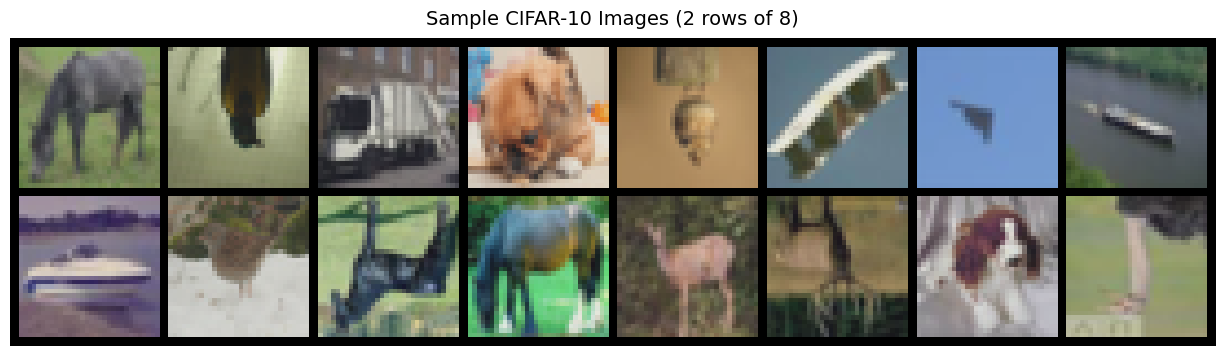

Labels row 1: ['Horse', 'Bird', 'Truck', 'Dog', 'Bird', 'Airplane', 'Airplane', 'Ship']
Labels row 2: ['Ship', 'Bird', 'Horse', 'Horse', 'Deer', 'Deer', 'Dog', 'Bird']


In [9]:
#@title visualize 16 images
import matplotlib.pyplot as plt
import torch
import torchvision

# 1. Fetch a batch of 16 images and labels from your dataset
batch_size = 16
sample_loader = torch.utils.data.DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
images, labels = next(iter(sample_loader))  # shape: (16, C, H, W)

# 2. Un-normalize the images for display (assuming standard CIFAR-10 mean/std)
# If your eval_transform / train_transform uses Normalize(mean, std), revert it:
mean = torch.tensor([0.4914, 0.4822, 0.4465]).view(3, 1, 1)
std = torch.tensor([0.2023, 0.1994, 0.2010]).view(3, 1, 1)

images_unnorm = images * std + mean
images_unnorm = torch.clamp(images_unnorm, 0, 1)

# 3. Create a single grid with nrow=8 (arranges 16 images into 2 rows of 8)
grid = torchvision.utils.make_grid(images_unnorm, nrow=8, padding=2)

# 4. Convert PyTorch tensor (C, H, W) to Matplotlib format (H, W, C) & plot
plt.figure(figsize=(16, 4))
plt.imshow(grid.permute(1, 2, 0).numpy())
plt.axis('off')
plt.title('Sample CIFAR-10 Images (2 rows of 8)', fontsize=14, pad=10)
plt.show()

# Print corresponding class names
class_names = [CLASSES[lbl.item()] for lbl in labels]
print("Labels row 1:", class_names[:8])
print("Labels row 2:", class_names[8:])

---
## 0.2 Choosing our pretrained model!

> The pretrained model (aka Backbone) will act as a feature extractor! Freeing us from making the model learn everything about our data from ground zero.

> Let's explore our options!

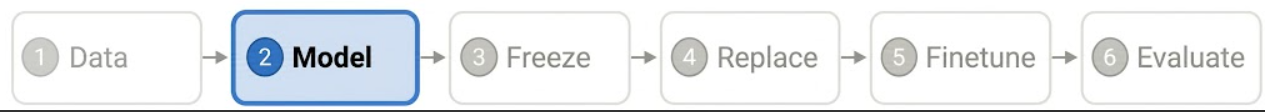

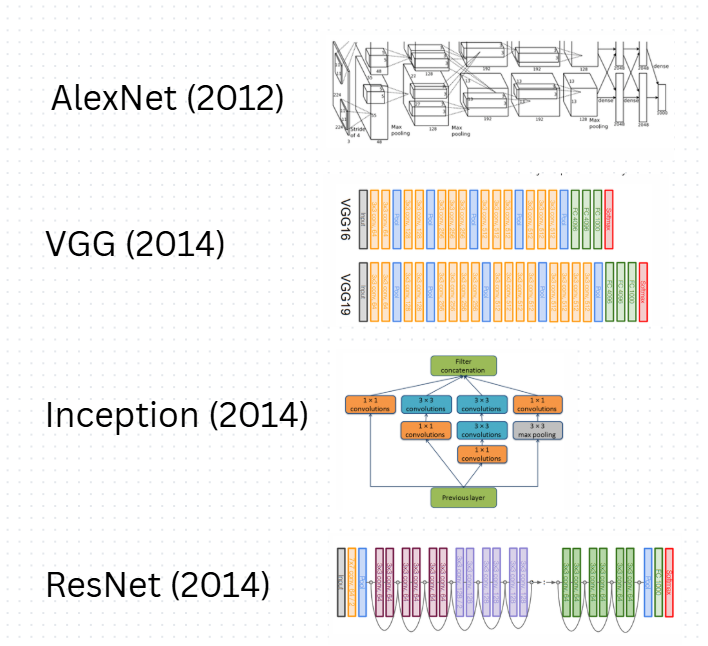

Each paper of the Computer Vision literature are here: [KAUST Academy listing famous CV paper](https://github.com/KAUST-Academy/2025_Advanced-Ai/tree/main/Slides/Papers)

> Choosing the backbone is a critical process that require alot of reading about it in three things mainly:

- Data - what data this model knows?
- Architecture - does this architecture solve my problem?
- Parameter count - how big this model?

**The main families (what to know about each):**

- **Classic CNNs — ResNet / ResNeXt / DenseNet.** ResNet's skip connections made very deep
  nets trainable. `resnet18/34/50/101` are dependable, well-understood defaults; ResNet-50 is
  the classic "just works" baseline.
- **Efficiency-first — MobileNetV2/V3, ShuffleNet, SqueezeNet.** Designed for phones and
  microcontrollers: depthwise-separable convolutions cut compute drastically. First choice
  when latency/RAM matter (phones, microcontrollers).
- **Compound-scaled — EfficientNet (B0–B7), EfficientNetV2.** Balance depth/width/resolution
  for excellent accuracy-per-FLOP. `efficientnet_b0` is small yet strong.
- **Modernised ConvNets — ConvNeXt (T/S/B/L), RegNet.** ConvNeXt is a ResNet redesigned with
  transformer-era tricks; matches ViTs while staying a pure CNN.
- **Vision Transformers — ViT, DeiT, Swin, MaxViT.** Attention-based; strongest with lots of
  data or big pretraining. Swin/MaxViT add locality back for efficiency.
- **Hybrids & big pretraining — CoAtNet, CLIP/DINO/SigLIP backbones.** Convolution+attention,
  or self-/language-supervised pretraining that transfers remarkably well.

> **Where to get them:** the **Hugging Face Hub** hosts all of these — as `transformers` models
> (`AutoModelForImageClassification`, used here) and as **`timm`** models, whose weights also live on the
> Hub (`timm.create_model("hf_hub:timm/<name>", pretrained=True)`). `torchvision.models` ships the
> staples with no extra install.

In [10]:
#@title loading chosen the model
from transformers import AutoModelForImageClassification

Backbone = "microsoft/resnet-50"
model = AutoModelForImageClassification.from_pretrained(Backbone).to(DEVICE).eval()

n_params = lambda m: sum(p.numel() for p in m.parameters())

print(f"{type(model).__name__} | {n_params(model) / 1e6:.1f} M parameters")
print("top level :", [n for n, _ in model.named_children()])
print("backbone  :", [n for n, _ in model.base_model.named_children()])
print("head      :", model.classifier)
print(f"config    : num_labels={model.config.num_labels} | id2label[0]={model.config.id2label[0]!r}\n")

config.json:   0%|          | 0.00/69.6k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  102MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

ResNetForImageClassification | 25.6 M parameters
top level : ['resnet', 'classifier']
backbone  : ['embedder', 'encoder', 'pooler']
head      : Sequential(
  (0): Flatten(start_dim=1, end_dim=-1)
  (1): Linear(in_features=2048, out_features=1000, bias=True)
)
config    : num_labels=1000 | id2label[0]='tench, Tinca tinca'



In [11]:
#@title inspect the raw model
print(model)

ResNetForImageClassification(
  (resnet): ResNetModel(
    (embedder): ResNetEmbeddings(
      (embedder): ResNetConvLayer(
        (convolution): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
        (normalization): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (activation): ReLU()
      )
      (pooler): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
    )
    (encoder): ResNetEncoder(
      (stages): ModuleList(
        (0): ResNetStage(
          (layers): Sequential(
            (0): ResNetBottleNeckLayer(
              (shortcut): ResNetShortCut(
                (convolution): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
                (normalization): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
              )
              (layer): Sequential(
                (0): ResNetConvLayer(
                  (convolution): Conv2d(64

In [12]:
#@title inspect the model and summary of the model

print(f"{type(model).__name__} | Total Params: {sum(p.numel() for p in model.parameters()) / 1e6:.1f}M")
print(f"Config: num_labels={model.config.num_labels} | id2label[0]={model.config.id2label[0]!r}\n")

# Summarize parameters per architectural block
blocks = {
    "stem (embedder)": model.base_model.embedder,
    **{f"stage {i+1}": stage for i, stage in enumerate(model.base_model.encoder.stages)},
    "head (classifier)": model.classifier,
}

print(f"{'Block':<20} {'Parameters (M)':>15}")
print("-" * 36)
for name, block in blocks.items():
    p_count = sum(p.numel() for p in block.parameters()) / 1e6
    print(f"{name:<20} {p_count:>15.2f}M")

ResNetForImageClassification | Total Params: 25.6M
Config: num_labels=1000 | id2label[0]='tench, Tinca tinca'

Block                 Parameters (M)
------------------------------------
stem (embedder)                 0.01M
stage 1                         0.22M
stage 2                         1.22M
stage 3                         7.10M
stage 4                        14.96M
head (classifier)               2.05M


---
## 0.3 Freezing the backbone

**Freezing** = telling autograd not to compute gradients for some parameters (`requires_grad = False`).
Frozen weights never change, and we hand the optimizer only the trainable ones.

In [13]:
# Print module-level summary of trainable parameters
for name, module in model.named_children(): # <- .named_children() is an inherited function from nn.Module
    requires_grad = any(p.requires_grad for p in module.parameters())
    print(f"{name:<15} : requires_grad = {requires_grad}")

resnet          : requires_grad = True
classifier      : requires_grad = True


In [14]:
#@title freezing the backbone parameters
for param in model.parameters():
    param.requires_grad = False

In [15]:
for name, module in model.named_children():
    requires_grad = any(p.requires_grad for p in module.parameters())
    print(f"{name:<15} : requires_grad = {requires_grad}")

resnet          : requires_grad = False
classifier      : requires_grad = False


---
## 0.4 Replacing the classifier of backbone

> ResNet50 classifier layers, classifies 1000 classes! while our problem require to classify only 10; this prompts us to remove it and replace it with a newly initialized classifier.

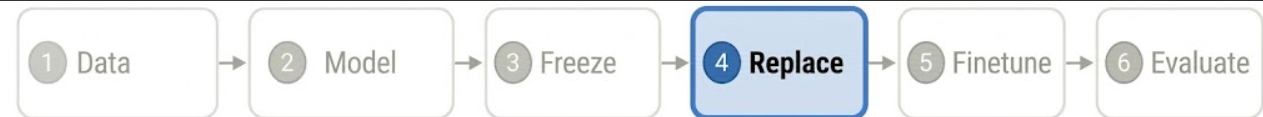

In [16]:
import torch.nn as nn

# Replace the classifier for 10 output classes
num_classes = 10
in_features = model.config.hidden_sizes[-1]  # 2048

# Replace classifier with Flatten + Linear
model.classifier = nn.Sequential(
    nn.Flatten(start_dim=1),
    nn.Linear(in_features, num_classes)
).to(DEVICE)

model.config.num_labels = num_classes

In [17]:
for name, module in model.named_children():
    requires_grad = any(p.requires_grad for p in module.parameters())
    print(f"{name:<15} : requires_grad = {requires_grad}")

resnet          : requires_grad = False
classifier      : requires_grad = True


---
## 0.5 Finetuning the frozen model!

### Two ways:

Linear probe vs. full fine-tuning on big data

Two runs, same data, same number of epochs:

- **Linear probe** — backbone frozen, only the 20 k parameters of the new head train, at `LR_HEAD`.
- **Full fine-tuning** — all 23.5 M parameters train, at the 10× smaller `LR_FULL` so the pretrained
  features are adjusted, not overwritten.

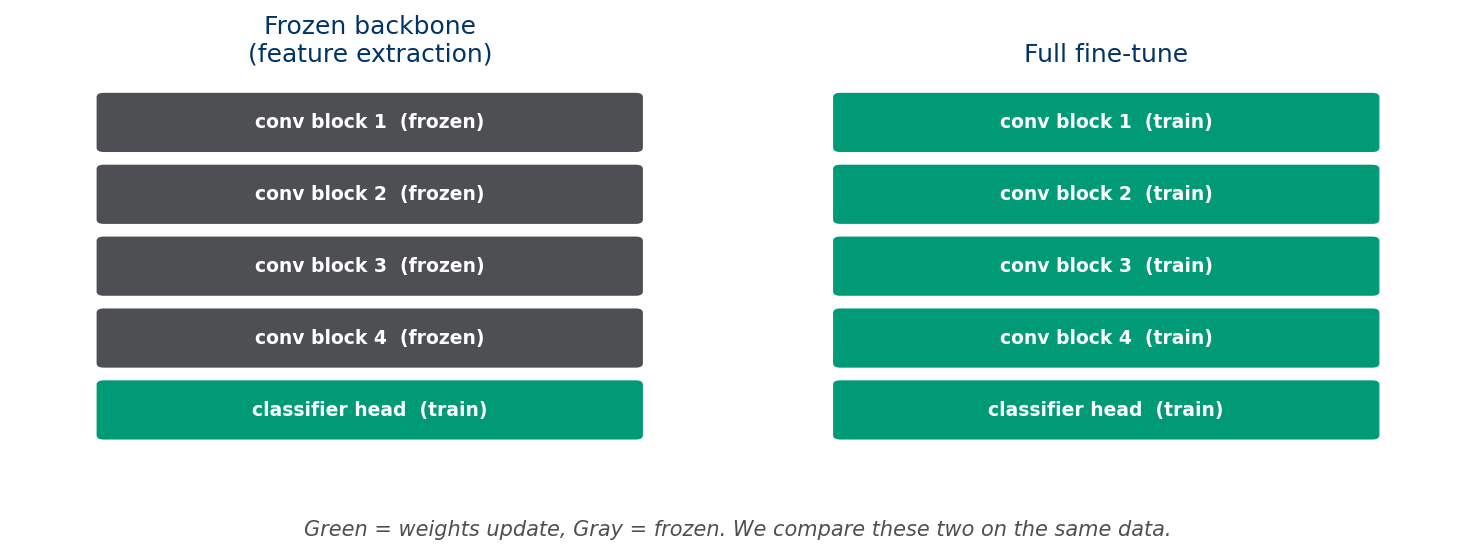

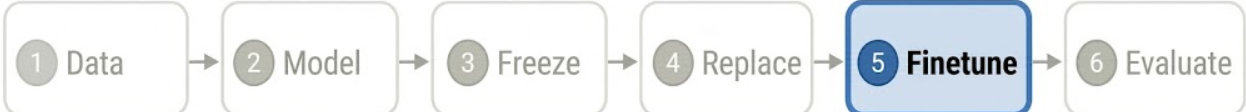

In [18]:
#@title training and evaluation functions

import time
import torch
import torch.nn as nn
from torch.optim import AdamW
from torch.optim.lr_scheduler import CosineAnnealingLR

# --- 1. Train Step ---
def train_step(model, dataloader, criterion, optimizer, device):
    model.train()
    total_loss, correct, total = 0.0, 0, 0

    for images, labels in dataloader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(images).logits  # HuggingFace model output
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * images.size(0)
        preds = outputs.argmax(dim=1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)

    return total_loss / total, correct / total

# --- 2. Validation Step ---
@torch.no_grad()
def eval_step(model, dataloader, criterion, device):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0

    for images, labels in dataloader:
        images, labels = images.to(device), labels.to(device)

        outputs = model(images).logits
        loss = criterion(outputs, labels)

        total_loss += loss.item() * images.size(0)
        preds = outputs.argmax(dim=1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)

    return total_loss / total, correct / total

# --- 3. Main Fit Loop ---
def fit(model, train_loader, val_loader, criterion, optimizer, scheduler, epochs, device):
    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}

    print(f"{'Epoch':<7} | {'Train Loss':<10} | {'Train Acc':<10} | {'Val Loss':<10} | {'Val Acc':<10} | {'Time (s)':<8}")
    print("-" * 72)

    for epoch in range(1, epochs + 1):
        start_time = time.time()

        train_loss, train_acc = train_step(model, train_loader, criterion, optimizer, device)
        val_loss, val_acc = eval_step(model, val_loader, criterion, device)

        if scheduler:
            scheduler.step()

        elapsed = time.time() - start_time

        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)

        print(f"{epoch:<7} | {train_loss:<10.4f} | {train_acc:<10.4f} | {val_loss:<10.4f} | {val_acc:<10.4f} | {elapsed:<8.2f}")

    return history

In [19]:
# --- 4. Setup & Execute Training ---
epochs = 5
criterion = nn.CrossEntropyLoss()
lr=1e-3
optimizer = AdamW(filter(lambda p: p.requires_grad, model.parameters()), lr=lr)
scheduler = CosineAnnealingLR(optimizer, T_max=epochs)

In [20]:
#@title training the model
history = fit(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion,
    optimizer=optimizer,
    scheduler=scheduler,
    epochs=epochs,
    device=DEVICE
)

Epoch   | Train Loss | Train Acc  | Val Loss   | Val Acc    | Time (s)
------------------------------------------------------------------------
1       | 1.8815     | 0.3635     | 2.0787     | 0.4100     | 7.38    
2       | 1.7159     | 0.4137     | 2.2379     | 0.4254     | 4.50    
3       | 1.6757     | 0.4240     | 5.8806     | 0.4240     | 4.52    
4       | 1.6577     | 0.4322     | 2.8498     | 0.4344     | 4.46    
5       | 1.6531     | 0.4332     | 3.3656     | 0.4354     | 4.46    


The time of this training is taking around 20 second for each epoch! Can we speed it up?

Yes, let's modify our dataloaders to fetch and load in parallel.

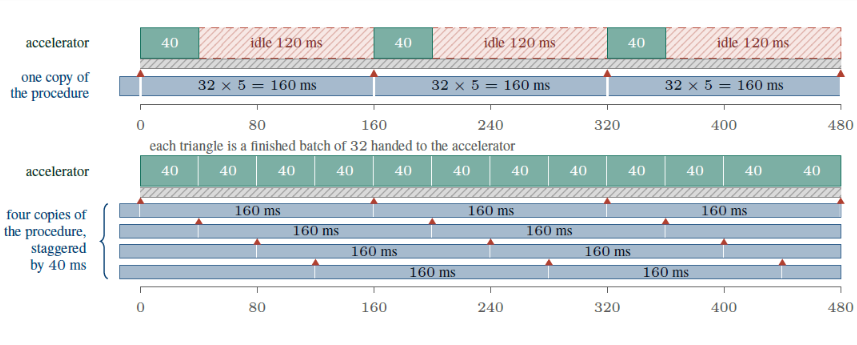

In [21]:
#@title see the system capabilites
print(f'cpu workers {os.cpu_count()}')

cpu workers 48


In [22]:
BATCH_SIZE = 64
NUM_WORKERS = 6

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

In [23]:
history = fit(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion,
    optimizer=optimizer,
    scheduler=scheduler,
    epochs=epochs,
    device=DEVICE
)

Epoch   | Train Loss | Train Acc  | Val Loss   | Val Acc    | Time (s)
------------------------------------------------------------------------
1       | 1.6478     | 0.4348     | 2.4501     | 0.4322     | 2.75    
2       | 1.6406     | 0.4366     | 2.2075     | 0.4268     | 2.73    
3       | 1.6503     | 0.4323     | 3.1647     | 0.4340     | 2.80    
4       | 1.6421     | 0.4326     | 2.4374     | 0.4278     | 2.77    
5       | 1.6430     | 0.4322     | 5.7706     | 0.4222     | 2.73    


---
## 0.6 Evaluation and Visualizations!


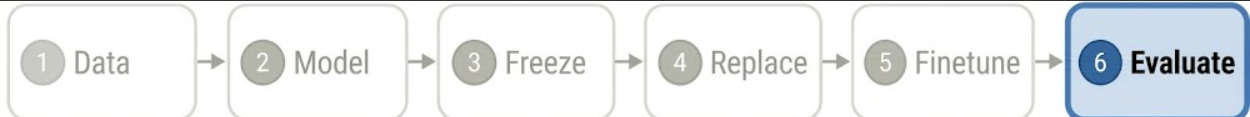

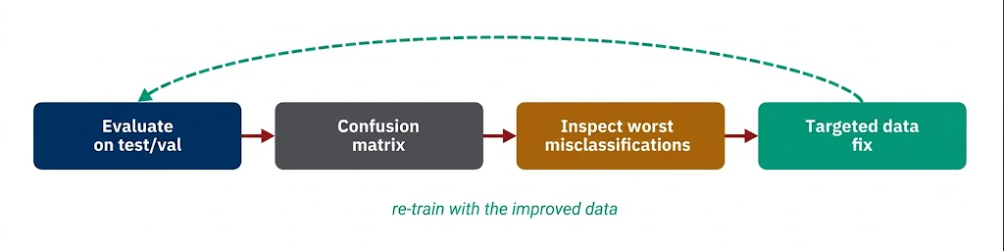

In [24]:
#@title visualization function
import matplotlib.pyplot as plt

def plot_history(history):
    epochs = range(1, len(history["train_loss"]) + 1)

    plt.figure(figsize=(10, 4))

    # Plot Losses
    plt.subplot(1, 2, 1)
    plt.plot(epochs, history["train_loss"], label="Train Loss")
    plt.plot(epochs, history["val_loss"], label="Val Loss")
    plt.title("Loss")
    plt.xlabel("Epoch")
    plt.legend()

    # Plot Accuracies
    plt.subplot(1, 2, 2)
    plt.plot(epochs, history["train_acc"], label="Train Acc")
    plt.plot(epochs, history["val_acc"], label="Val Acc")
    plt.title("Accuracy")
    plt.xlabel("Epoch")
    plt.legend()

    plt.tight_layout()
    plt.show()

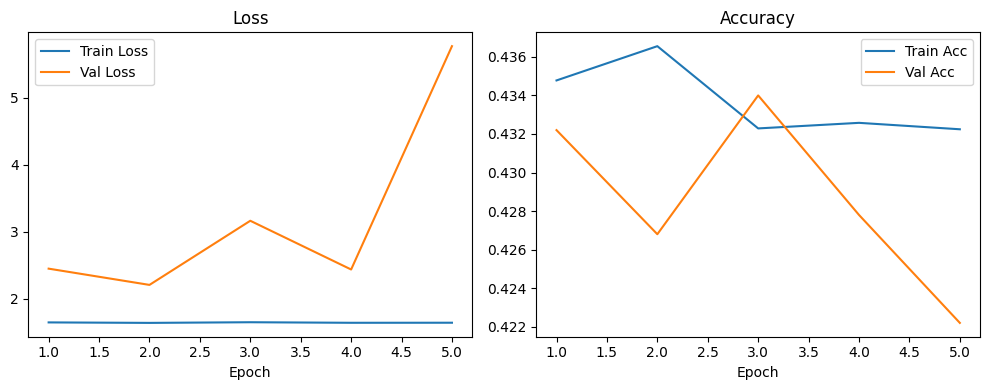

In [25]:
plot_history(history)

In [26]:
#@title predictions
@torch.no_grad()
def get_predictions(model, dataloader, device=DEVICE):
    model.eval()
    all_logits, all_labels = [], []

    for images, labels in dataloader:
        images = images.to(device, non_blocking=True)
        with torch.amp.autocast('cuda', enabled=(device == 'cuda')):
            logits = model(images).logits
        all_logits.append(logits.cpu())
        all_labels.append(labels)

    logits = torch.cat(all_logits, dim=0)
    labels = torch.cat(all_labels, dim=0)
    probs = logits.softmax(dim=1).numpy()
    preds = logits.argmax(dim=1).numpy()

    return labels.numpy(), preds, probs

In [27]:
#@title visualization
import numpy as np
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

def evaluate_and_visualize(y_true, y_pred, probs, dataset, class_names, title_prefix="Model"):
    # 1. Classification Report
    print(f"=== {title_prefix} Classification Report ===")
    print(classification_report(y_true, y_pred, target_names=class_names, digits=3))

    # 2. Confusion Matrix
    fig, ax = plt.subplots(figsize=(8, 7))
    ConfusionMatrixDisplay.from_predictions(
        y_true, y_pred,
        display_labels=class_names,
        normalize="true",
        values_format=".2f",
        cmap="Blues",
        colorbar=False,
        ax=ax,
        xticks_rotation=45
    )
    ax.set_title(f"{title_prefix} - Row-Normalized Confusion Matrix")
    plt.tight_layout()
    plt.show()

    # 3. Top 10 Most Confident Mistakes
    conf = probs.max(axis=1)
    wrong = np.where(y_pred != y_true)[0]
    worst = wrong[np.argsort(-conf[wrong])][:10]

    if len(worst) == 0:
        print("No mistakes found!")
        return

    fig, axes = plt.subplots(2, 5, figsize=(15, 6.5))
    for ax, i in zip(axes.flat, worst):
        img_tensor, _ = dataset[i]
        img_np = img_tensor.permute(1, 2, 0).numpy()

        # Rescale [min, max] -> [0, 1] for visual display
        img_np = (img_np - img_np.min()) / (img_np.max() - img_np.min() + 1e-8)

        ax.imshow(img_np)
        ax.axis("off")
        ax.set_title(
            f"True: {class_names[y_true[i]]}\nPred: {class_names[y_pred[i]]} ({conf[i]:.0%})",
            fontsize=9,
            color="red"
        )

    for ax in axes.flat[len(worst):]:
        ax.axis("off")

    plt.suptitle(f"{title_prefix} - Top 10 Most Confident Mistakes", fontsize=14)
    plt.tight_layout()
    plt.show()

=== Phase 1 (Classifier Only) Classification Report ===
              precision    recall  f1-score   support

    Airplane      0.439     0.515     0.474      1000
  Automobile      0.494     0.548     0.520      1000
        Bird      0.366     0.339     0.352      1000
         Cat      0.342     0.345     0.343      1000
        Deer      0.411     0.327     0.364      1000
         Dog      0.461     0.432     0.446      1000
        Frog      0.490     0.551     0.519      1000
       Horse      0.443     0.469     0.456      1000
        Ship      0.478     0.447     0.462      1000
       Truck      0.511     0.476     0.493      1000

    accuracy                          0.445     10000
   macro avg      0.444     0.445     0.443     10000
weighted avg      0.444     0.445     0.443     10000



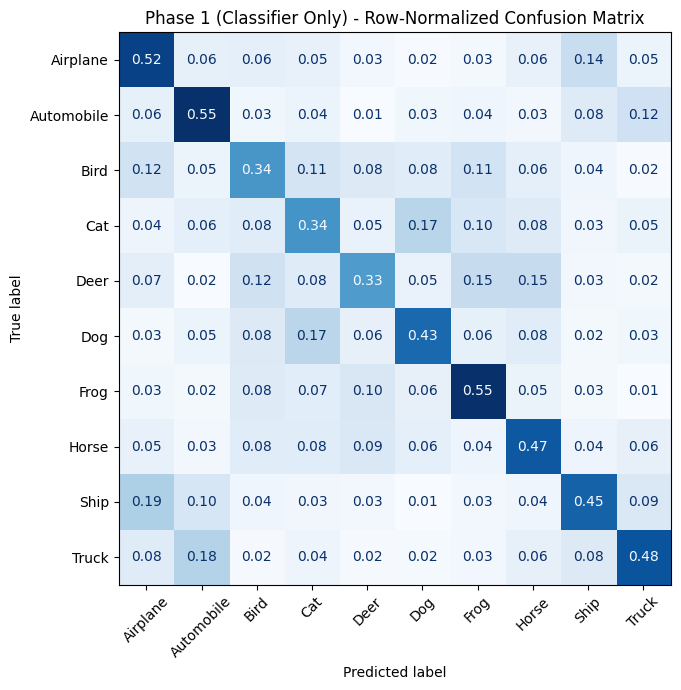

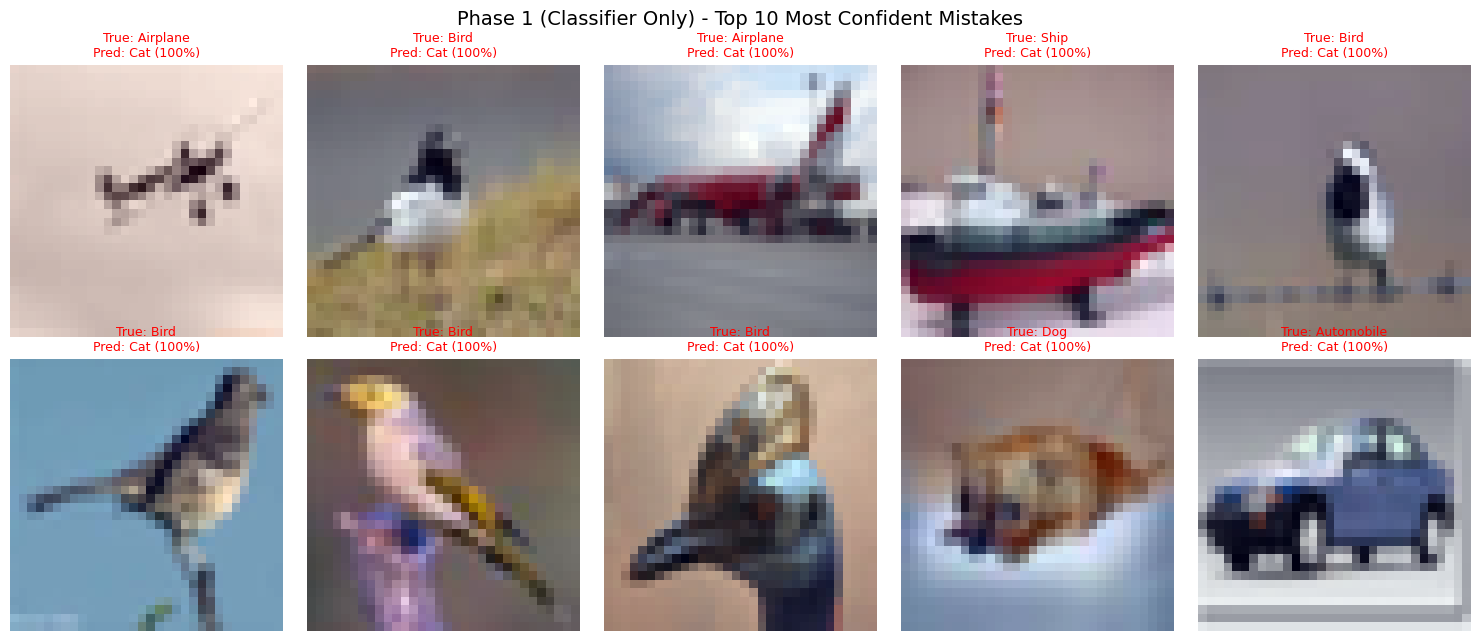

In [29]:
# Step 1: Extract logits and predictions
y_true, y_pred, probs = get_predictions(model, test_loader)

# Step 2: Generate metrics and plots
evaluate_and_visualize(
    y_true=y_true,
    y_pred=y_pred,
    probs=probs,
    dataset=test_dataset,
    class_names=CLASSES,
    title_prefix="Phase 1 (Classifier Only)"
)

---
## How to enhance?

#### - We trained the model but it achieved only 40% accuracy!

#### - Should we train more?

#### - Should we unfreeze more layers of the backbone?

#### - Should we look for another backbone?

#### - Should we regularize our model?

#### - Should we increase the size of the classifier?

#### - Are our hyperparameters even good?


## I.6 Bias, variance — and why the amount of data changes everything

Imagine training the same model many times, each time on a **different random sample** of training data
from the same source. The expected error on new data splits into three parts (Geman et al., 1992):

$$\mathbb{E}\big[(y - \hat f(x))^2\big] \;=\; \underbrace{\big(\mathbb{E}[\hat f(x)] - f(x)\big)^2}_{\text{bias}^2} \;+\; \underbrace{\mathbb{E}\big[(\hat f(x) - \mathbb{E}[\hat f(x)])^2\big]}_{\text{variance}} \;+\; \underbrace{\sigma^2}_{\text{noise}}$$

- **Bias** — the error that remains *on average*: the model is too simple (or too constrained) to capture
  the true pattern. High bias = **underfitting**.
- **Variance** — how much the learned model *changes* with the particular sample it saw. High variance =
  it learned the sample's quirks = **overfitting**.
- **Noise** — irreducible (e.g. ambiguous or mislabelled images).

More flexible models lower bias but raise variance. **More data lowers variance** — the quirks of any one
sample average out — so with lots of data you can afford a very flexible model. The demo below fits
polynomials (simple → very flexible) to noisy samples of a sine curve, 30 times each, with **15** and with
**500** points.

In [30]:
# Unfreeze only the last stage (Stage 4) of the backbone
for param in model.base_model.encoder.stages[-1].parameters():
    param.requires_grad = True

# Verify requires_grad status per block
for name, module in model.named_children():
    requires_grad = any(p.requires_grad for p in module.parameters())
    print(f"{name:<15} : requires_grad = {requires_grad}")

resnet          : requires_grad = True
classifier      : requires_grad = True


In [31]:
# Print requires_grad status for backbone sub-modules and classifier
print("--- Backbone Sub-modules ---")
print(f"{'embedder':<20} : requires_grad = {any(p.requires_grad for p in model.base_model.embedder.parameters())}")

for i, stage in enumerate(model.base_model.encoder.stages):
    requires_grad = any(p.requires_grad for p in stage.parameters())
    print(f"{f'stage {i + 1}':<20} : requires_grad = {requires_grad}")

print("\n--- Top-level Modules ---")
for name, module in model.named_children():
    requires_grad = any(p.requires_grad for p in module.parameters())
    print(f"{name:<20} : requires_grad = {requires_grad}")

--- Backbone Sub-modules ---
embedder             : requires_grad = False
stage 1              : requires_grad = False
stage 2              : requires_grad = False
stage 3              : requires_grad = False
stage 4              : requires_grad = True

--- Top-level Modules ---
resnet               : requires_grad = True
classifier           : requires_grad = True


In [32]:
# Re-initialize optimizer and scheduler for fine-tuning
epochs = 15
optimizer = AdamW(filter(lambda p: p.requires_grad, model.parameters()), lr=1e-4)
scheduler = CosineAnnealingLR(optimizer, T_max=epochs)

# Continue training
fine_tune_history = fit(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion,
    optimizer=optimizer,
    scheduler=scheduler,
    epochs=epochs,
    device=DEVICE
)

Epoch   | Train Loss | Train Acc  | Val Loss   | Val Acc    | Time (s)
------------------------------------------------------------------------
1       | 1.5866     | 0.4490     | 2.7055     | 0.4514     | 3.66    
2       | 1.5036     | 0.4759     | 1.8089     | 0.4756     | 3.54    
3       | 1.4416     | 0.4923     | 1.6550     | 0.4900     | 3.46    
4       | 1.3871     | 0.5134     | 1.7336     | 0.4916     | 3.55    
5       | 1.3431     | 0.5280     | 1.5517     | 0.5144     | 3.61    
6       | 1.3137     | 0.5378     | 1.5627     | 0.5210     | 3.57    
7       | 1.2786     | 0.5487     | 1.7549     | 0.5326     | 3.54    
8       | 1.2639     | 0.5526     | 1.6160     | 0.5244     | 3.54    
9       | 1.2443     | 0.5611     | 1.3999     | 0.5380     | 3.49    
10      | 1.2277     | 0.5669     | 1.3632     | 0.5412     | 3.68    
11      | 1.2132     | 0.5680     | 1.4070     | 0.5394     | 3.48    
12      | 1.2066     | 0.5727     | 1.7238     | 0.5412     | 3.67    
13  

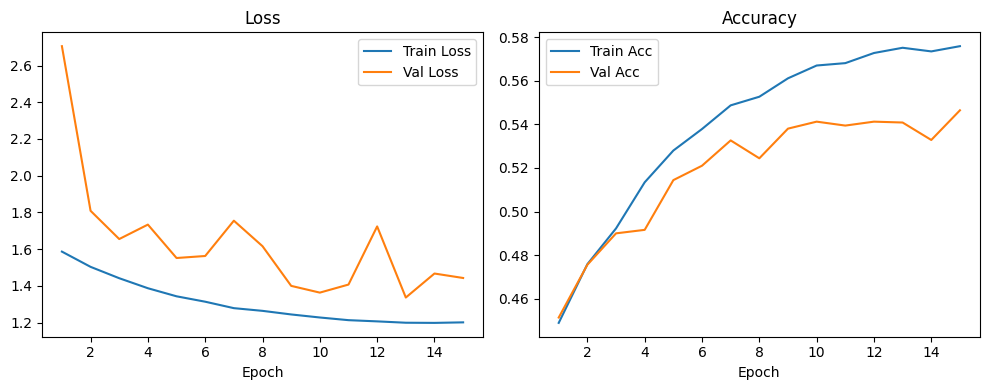

In [33]:
# Plot fine-tuning progress
plot_history(fine_tune_history)

---
## Stabilize Training & Making training fast: mixed precision

#### The validation loss is oscillating, how to solve this issue?

#### Let's also make the training much faster!



The next section trains a dozen models, so speed now matters. A training step has two halves that should
**overlap**: the CPU *prepares* the next batch (read JPEG, decode, augment) while the GPU *computes* on the
current one. If the CPU is too slow, the GPU sits idle.

| Knob | What it does |
|---|---|
| `num_workers` | **parallel fetching**: N worker processes load and augment batches in the background |
| `prefetch_factor` | how many batches *each* worker keeps ready in advance |
| `persistent_workers` | keep workers alive between epochs instead of re-spawning them |
| `pin_memory` | put batches in **page-locked** CPU memory, which the GPU can copy from directly (DMA) |
| `.to(device, non_blocking=True)` | **off-loading** the copy: with pinned memory it runs asynchronously, overlapping with compute |
| mixed precision (`torch.autocast`) | matrix math in 16-bit floats on the GPU's tensor cores: faster, half the activation memory (Micikevicius et al., 2018) |
| `channels_last` | a memory layout convolutions on tensor cores prefer |

**bfloat16 vs float16.** bfloat16 (L4, A100, H100) keeps float32's range, so it needs no loss scaling.
float16 (T4) has a narrow range: tiny gradients underflow to zero, so a `GradScaler` multiplies the loss up
before `backward()` and divides the gradients back down before the optimizer step.

**📚 Read & learn**
- [PyTorch — *Performance Tuning Guide*](https://pytorch.org/tutorials/recipes/recipes/tuning_guide.html) — data loading, AMP, `channels_last`, and more.
- [PyTorch — *Automatic Mixed Precision recipe*](https://pytorch.org/tutorials/recipes/recipes/amp_recipe.html) — `autocast` + `GradScaler`, step by step.

In [34]:
#@title Advance training function

# --- 1. Upgraded Train Step (Mixed Precision + Grad Clipping) ---
def train_step_fast(model, dataloader, criterion, optimizer, scaler, device, max_norm=1.0):
    model.train()
    total_loss, correct, total = 0.0, 0, 0

    for images, labels in dataloader:
        images, labels = images.to(device, non_blocking=True), labels.to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)  # Faster than zero_grad()

        # Mixed precision forward pass
        with torch.amp.autocast('cuda', enabled=(device == 'cuda')):
            outputs = model(images).logits
            loss = criterion(outputs, labels)

        # Scaled backward pass
        scaler.scale(loss).backward()

        # Gradient Clipping
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm)

        scaler.step(optimizer)
        scaler.update()

        total_loss += loss.item() * images.size(0)
        preds = outputs.argmax(dim=1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)

    return total_loss / total, correct / total

# --- 2. Upgraded Validation Step (Mixed Precision) ---
@torch.no_grad()
def eval_step_fast(model, dataloader, criterion, device):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0

    for images, labels in dataloader:
        images, labels = images.to(device, non_blocking=True), labels.to(device, non_blocking=True)

        with torch.amp.autocast('cuda', enabled=(device == 'cuda')):
            outputs = model(images).logits
            loss = criterion(outputs, labels)

        total_loss += loss.item() * images.size(0)
        preds = outputs.argmax(dim=1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)

    return total_loss / total, correct / total

# --- 3. Upgraded Fit Loop ---
def fit_fast(model, train_loader, val_loader, criterion, optimizer, scheduler, scaler, epochs, device, max_norm=1.0):
    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}

    print(f"{'Epoch':<7} | {'Train Loss':<10} | {'Train Acc':<10} | {'Val Loss':<10} | {'Val Acc':<10} | {'Time (s)':<8}")
    print("-" * 72)

    for epoch in range(1, epochs + 1):
        start_time = time.time()

        train_loss, train_acc = train_step_fast(model, train_loader, criterion, optimizer, scaler, device, max_norm)
        val_loss, val_acc = eval_step_fast(model, val_loader, criterion, device)

        if scheduler:
            scheduler.step()

        elapsed = time.time() - start_time

        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)

        print(f"{epoch:<7} | {train_loss:<10.4f} | {train_acc:<10.4f} | {val_loss:<10.4f} | {val_acc:<10.4f} | {elapsed:<8.2f}")

    return history

In [35]:
#@title Let's finetune again from zero the classifier!

# 1. Fresh model initialization
Backbone = "microsoft/resnet-50"
fresh_model = AutoModelForImageClassification.from_pretrained(Backbone).to(DEVICE)

# 2. Replace head
fresh_model.classifier = nn.Sequential(
    nn.Flatten(start_dim=1),
    nn.Linear(fresh_model.config.hidden_sizes[-1], 10)
).to(DEVICE)
fresh_model.config.num_labels = 10

# 3. Freeze backbone
for param in fresh_model.base_model.parameters():
    param.requires_grad = False

# 4. Initialize GradScaler, Optimizer & Scheduler
scaler = torch.amp.GradScaler('cuda', enabled=(DEVICE == 'cuda'))
criterion = nn.CrossEntropyLoss()
optimizer = AdamW(filter(lambda p: p.requires_grad, fresh_model.parameters()), lr=1e-3)
scheduler = CosineAnnealingLR(optimizer, T_max=5)

# Train Classifier (5 Epochs)
print("=== Phase 1: Training Classifier Only ===")
history_phase1 = fit_fast(
    model=fresh_model,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion,
    optimizer=optimizer,
    scheduler=scheduler,
    scaler=scaler,
    epochs=5,
    device=DEVICE,
    max_norm=1.0
)

Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

=== Phase 1: Training Classifier Only ===
Epoch   | Train Loss | Train Acc  | Val Loss   | Val Acc    | Time (s)
------------------------------------------------------------------------
1       | 1.8815     | 0.3646     | 1.9305     | 0.4208     | 3.49    
2       | 1.7148     | 0.4157     | 1.9922     | 0.4258     | 3.38    
3       | 1.6748     | 0.4250     | 2.5909     | 0.4282     | 3.28    
4       | 1.6553     | 0.4321     | 2.1645     | 0.4368     | 3.42    
5       | 1.6516     | 0.4297     | 1.9989     | 0.4324     | 3.58    


--- Phase 1: Classifier Head Training ---


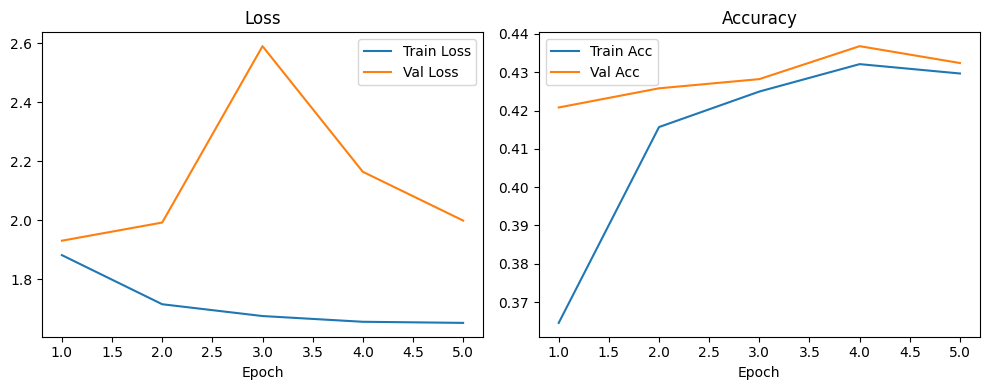

In [36]:
# Plot Phase 1: Training the head
print("--- Phase 1: Classifier Head Training ---")
plot_history(history_phase1)

In [37]:
#@title Training with the backbone.
# Unfreeze Stage 4 of backbone
for param in fresh_model.base_model.encoder.stages[-1].parameters():
    param.requires_grad = True

# Re-initialize Optimizer & Scheduler for fine-tuning
epochs = 15
optimizer = AdamW(filter(lambda p: p.requires_grad, fresh_model.parameters()), lr=1e-4)
scheduler = CosineAnnealingLR(optimizer, T_max=epochs)

# Fine-tune (15 Epochs)
print("\n=== Phase 2: Fine-Tuning Stage 4 + Head ===")
history_phase2 = fit_fast(
    model=fresh_model,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion,
    optimizer=optimizer,
    scheduler=scheduler,
    scaler=scaler,
    epochs=epochs,
    device=DEVICE,
    max_norm=1.0
)


=== Phase 2: Fine-Tuning Stage 4 + Head ===
Epoch   | Train Loss | Train Acc  | Val Loss   | Val Acc    | Time (s)
------------------------------------------------------------------------
1       | 1.5902     | 0.4509     | 2.8924     | 0.4550     | 4.37    
2       | 1.4993     | 0.4752     | 2.1025     | 0.4864     | 4.28    
3       | 1.4311     | 0.4969     | 1.9604     | 0.4984     | 4.51    
4       | 1.3746     | 0.5159     | 2.1321     | 0.5004     | 4.15    
5       | 1.3410     | 0.5266     | 1.7275     | 0.5154     | 4.25    
6       | 1.2960     | 0.5420     | 1.5184     | 0.5278     | 4.17    
7       | 1.2652     | 0.5527     | 2.1105     | 0.5328     | 4.43    
8       | 1.2401     | 0.5616     | 1.5883     | 0.5386     | 4.21    
9       | 1.2222     | 0.5693     | 1.8498     | 0.5548     | 4.18    
10      | 1.2067     | 0.5748     | 1.6082     | 0.5452     | 4.25    
11      | 1.1956     | 0.5770     | 1.8037     | 0.5432     | 4.19    
12      | 1.1844     | 0.5821 

--- Phase 2: Stage 4 Fine-Tuning ---


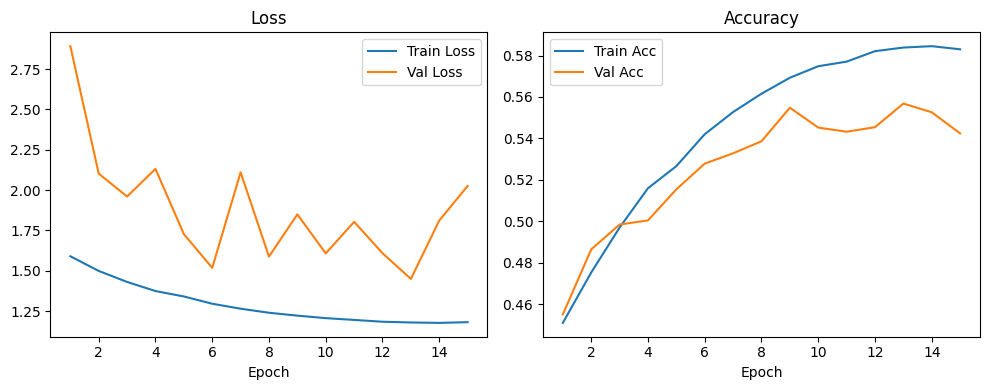

In [38]:
# Plot Phase 2: Fine-tuning Stage 4 + Head
print("--- Phase 2: Stage 4 Fine-Tuning ---")
plot_history(history_phase2)

### Log in to Weights & Biases

We track Part II's experiments in [Weights & Biases](https://wandb.ai) (W&B): every run's curves land on one
dashboard where you can overlay and compare them. One-time setup:

**Step 1** Login to `https://wandb.ai/site/`

**Step 2** Create an API key from `https://wandb.ai/settings` like the picture below:

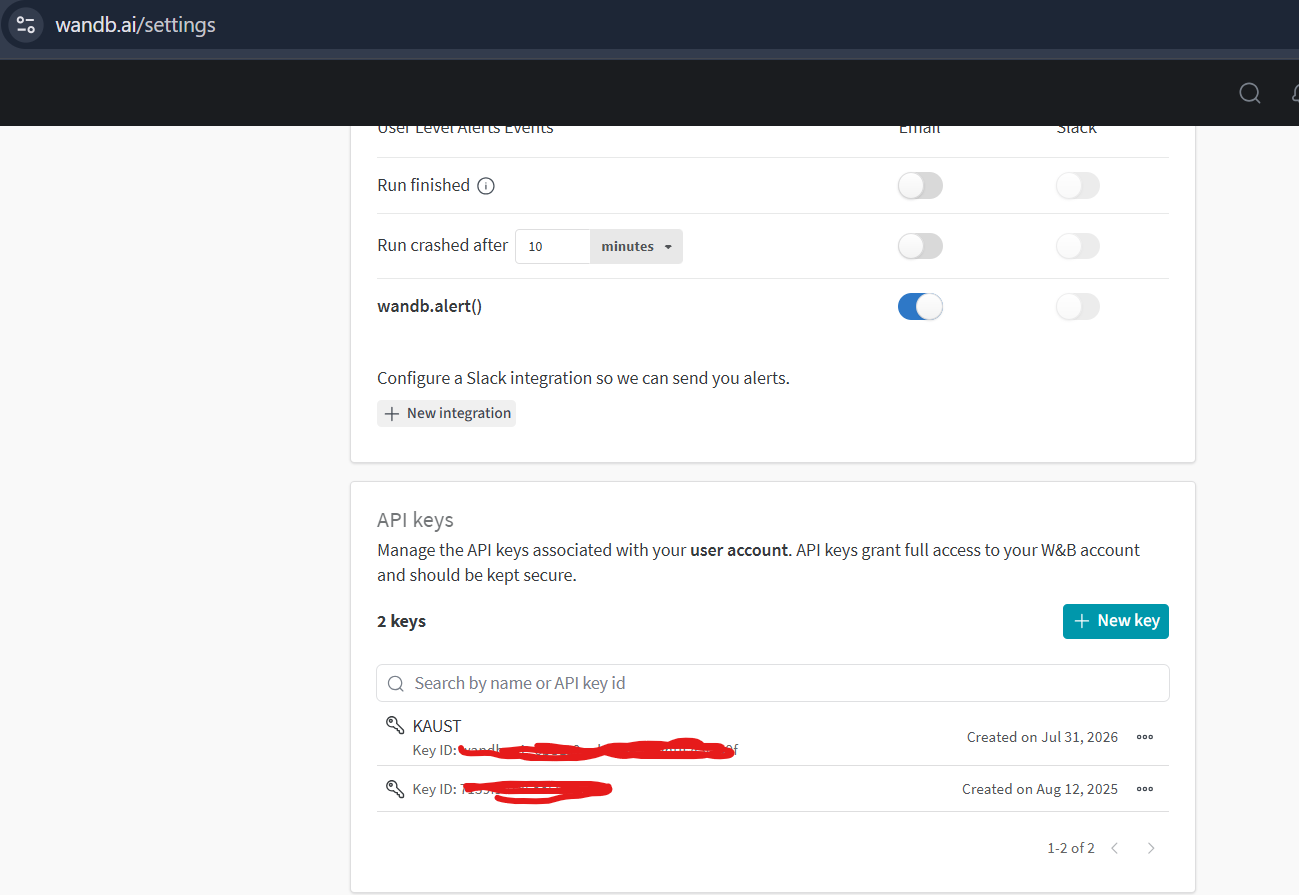

**Step 3** Create a project like the picture below:

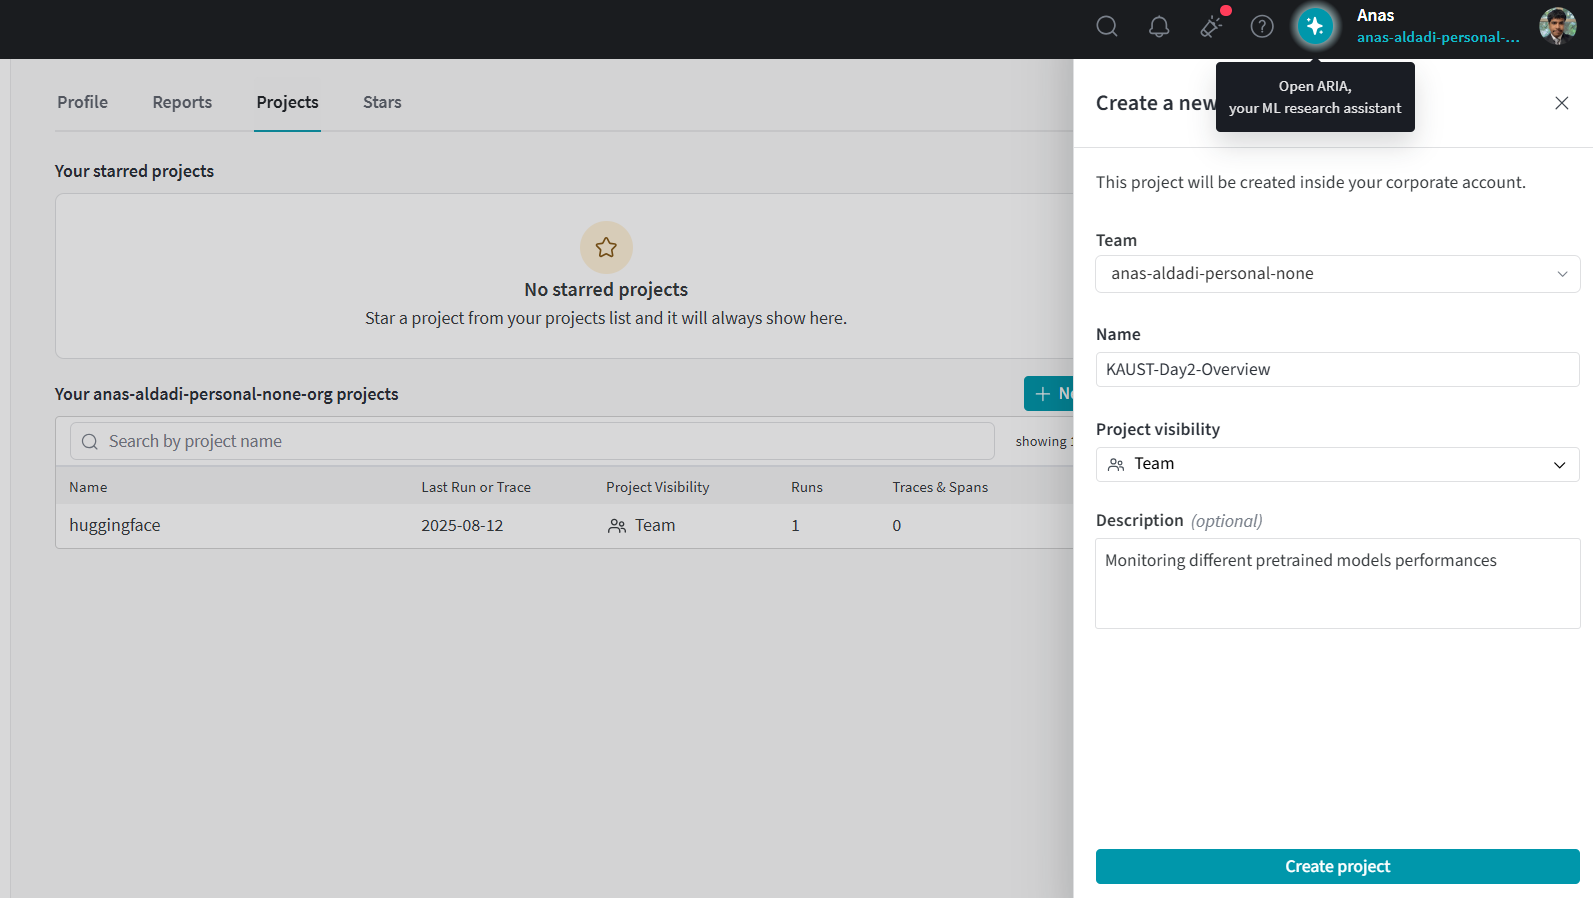

**Step 4** Run the cell below and paste your API key when asked. *(No account? Set `USE_WANDB = False` in
the config — everything still runs, and results are kept in memory instead.)*

In [39]:
#@title Weights and Biases
import os, getpass, wandb

# Configuration
USE_WANDB = True
WANDB_PROJECT = "KAUST-Day3-Finetuning"

if USE_WANDB:
    if not os.environ.get("WANDB_API_KEY"):
        os.environ["WANDB_API_KEY"] = getpass.getpass("Enter W&B API Key: ")
    wandb.login()
    print(f"W&B Ready | Project: {WANDB_PROJECT}")

def start_run(name, config=None):
    if not USE_WANDB:
        return None
    return wandb.init(project=WANDB_PROJECT, name=name, config=config)

Enter W&B API Key: ··········


/usr/local/lib/python3.13/dist-packages/notebook/notebookapp.py:191: SyntaxWarning: invalid escape sequence '\/'
  | |_| | '_ \/ _` / _` |  _/ -_)
wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from WANDB_API_KEY.
wandb: Currently logged in as: anas-aldadi-personal (anas-aldadi-personal-none) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


W&B Ready | Project: KAUST-Day3-Finetuning


In [40]:
def upload_run(history, run_name):
    run = start_run(run_name)
    if run:
        for epoch, (tl, ta, vl, va) in enumerate(zip(
            history["train_loss"], history["train_acc"],
            history["val_loss"], history["val_acc"]
        ), start=1):
            run.log({
                "epoch": epoch,
                "train/loss": tl,
                "train/acc": ta,
                "val/loss": vl,
                "val/acc": va
            })
        run.finish()

In [41]:
# Upload the 2 requested runs
upload_run(fine_tune_history, "Stage4-FineTuning-V1")
upload_run(history_phase2, "Stage4-FineTuning-Phase2")

epoch,▁▁▂▃▃▃▄▅▅▅▆▇▇▇█
train/acc,▁▂▃▅▅▆▇▇▇██████
train/loss,█▇▅▄▄▃▂▂▂▂▁▁▁▁▁
val/acc,▁▃▄▄▆▆▇▆▇█▇██▇█
val/loss,█▃▃▃▂▂▃▂▁▁▁▃▁▂▂
epoch,15
train/acc,0.5758
train/loss,1.20123
val/acc,0.5464
val/loss,1.44288


epoch,▁▁▂▃▃▃▄▅▅▅▆▇▇▇█
train/acc,▁▂▃▄▅▆▆▇▇▇█████
train/loss,█▆▅▄▄▃▂▂▂▁▁▁▁▁▁
val/acc,▁▃▄▄▅▆▆▇█▇▇▇██▇
val/loss,█▄▃▄▂▁▄▂▃▂▃▂▁▃▄
epoch,15
train/acc,0.583
train/loss,1.18175
val/acc,0.5424
val/loss,2.02601


**On the W&B dashboard** (*Sweeps* tab of your project): the **parallel-coordinates** plot draws every run as
a line through its hyperparameter values, coloured by `best_val_loss` — good runs cluster in a few ranges; the
**parameter importance** panel ranks which hyperparameters correlated most with the score; the overlaid
`val_loss` curves show which runs were stopped early.

Now when you open WandB project you will see all runs and compare which parameters are better, we can see you can overlay any metric — here, curves from different configurations side by side.

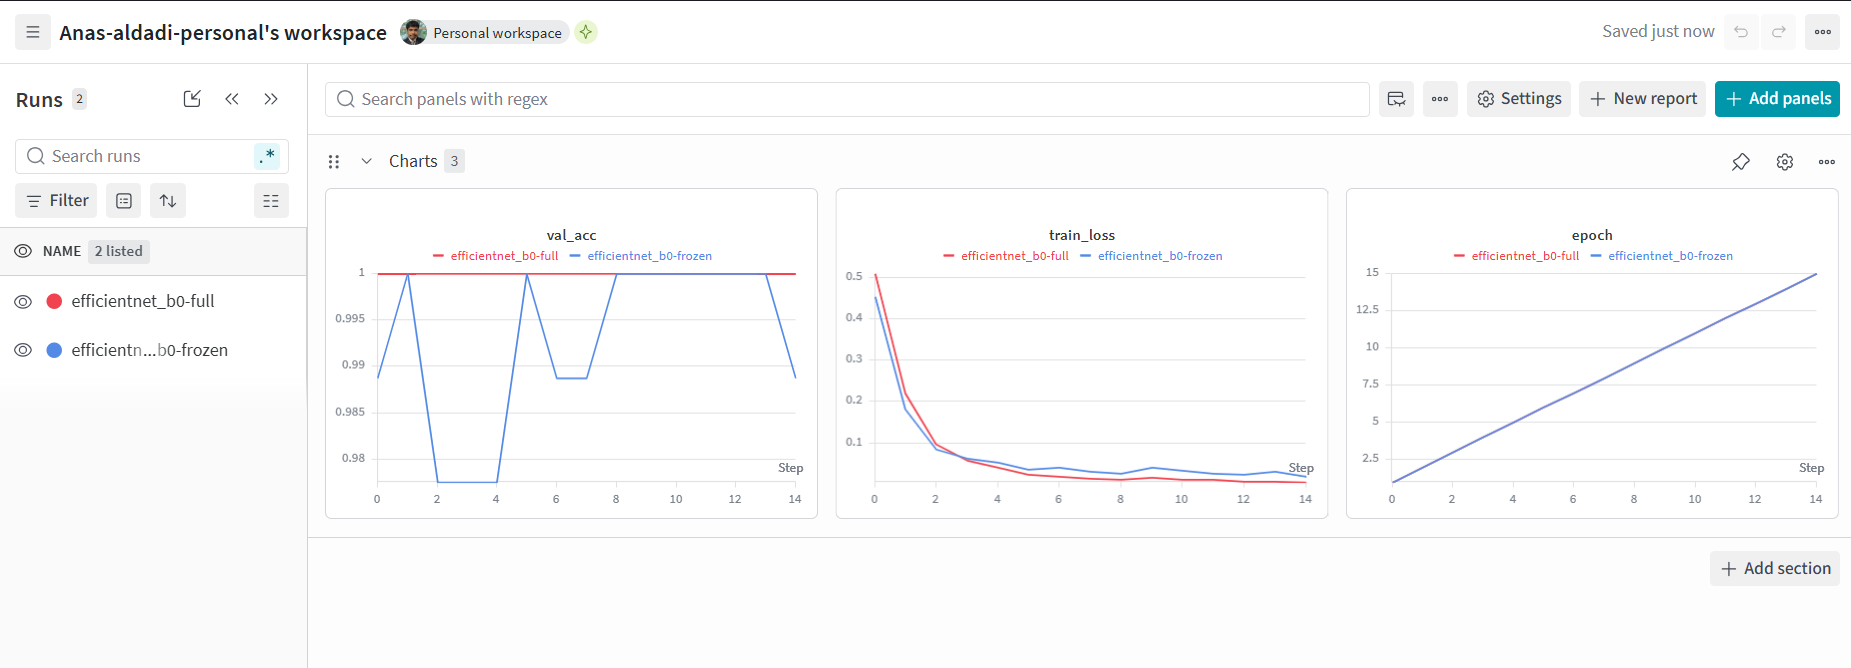

> **TensorBoard instead of W&B?** The same `fit` works with any logger that has a `log(dict)` method: wrap
> `torch.utils.tensorboard.SummaryWriter` (`writer.add_scalar(k, v, epoch)` for each key) and open it with
> `%load_ext tensorboard` and `%tensorboard --logdir runs`. W&B's advantage is the sweep machinery and the
> shared, browsable dashboard.

## Hyperparameter optimization — tracked in Weights & Biases

We picked `REGULARIZED`'s values by hand. A **hyperparameter search** tries many combinations and keeps the
best one, judged on the **validation** set:

- **Grid search** tries every combination — the cost explodes with each extra hyperparameter.
- **Random search** samples combinations; for the same budget it finds good values more often, because only
  a few hyperparameters usually matter (Bergstra & Bengio, 2012).
- **Bayesian optimization** fits a model of *score vs. hyperparameters* to the runs so far and picks the most
  promising next combination (Snoek et al., 2012).
- **Early termination** (Hyperband; Li et al., 2018) stops runs that are clearly losing, to spend the budget on
  promising ones.

**W&B Sweeps** run all of this for you: you describe the search space, and an *agent* trains one configuration
after another while the dashboard overlays every run — curves, a parallel-coordinates plot linking each
hyperparameter to the score, and a parameter-importance ranking. Without W&B, the same search runs locally as
a random search.

> ⚠️ **The search itself can overfit.** Ranking a dozen runs on a 50-image validation set (±7-point uncertainty)
> rewards lucky runs. That's why we rank on validation **loss**, and why the winner must still prove itself on
> the test set.

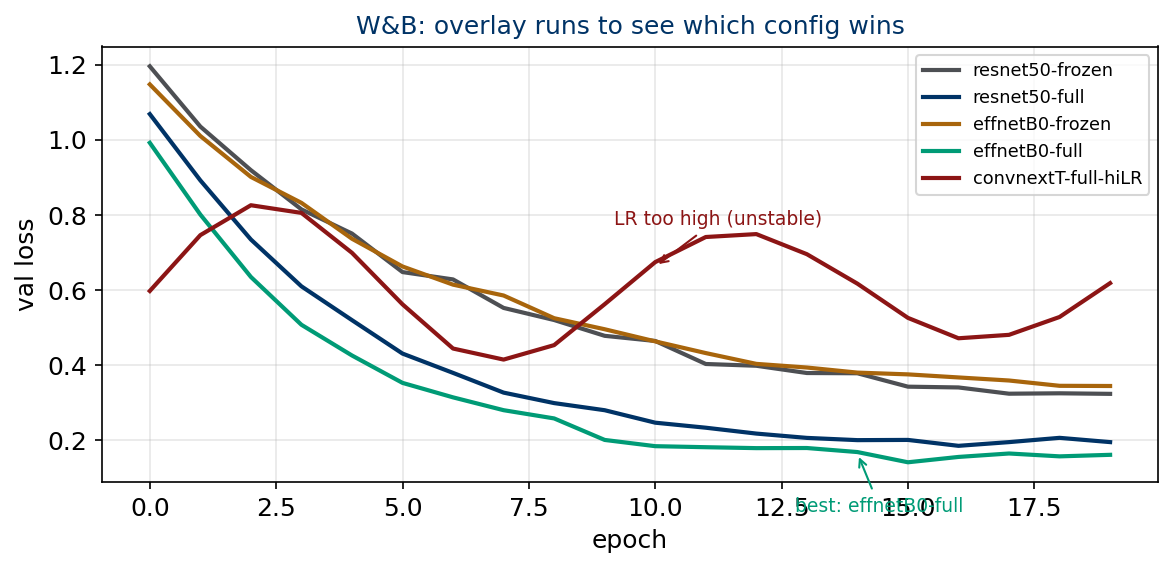

In [42]:
#@title 1. Model Initialization & Setup
def get_fresh_classifier_model(device=DEVICE):
    model = AutoModelForImageClassification.from_pretrained("microsoft/resnet-50").to(device)
    model.classifier = nn.Sequential(
        nn.Flatten(start_dim=1),
        nn.Linear(model.config.hidden_sizes[-1], 10)
    ).to(device)
    model.config.num_labels = 10
    return model

def freeze_all_except_stage4(model):
    for param in model.parameters():
        param.requires_grad = False
    for param in model.base_model.encoder.stages[-1].parameters():
        param.requires_grad = True
    for param in model.classifier.parameters():
        param.requires_grad = True

# 1. Initialize fresh model
base_model = get_fresh_classifier_model(DEVICE)

# 2. Freeze backbone completely for head training
for param in base_model.base_model.parameters():
    param.requires_grad = False

# 3. Train classifier head for 5 epochs
print("=== Phase 1: Pre-training Classifier Head (5 Epochs) ===")
scaler = torch.amp.GradScaler('cuda', enabled=(DEVICE == 'cuda'))
criterion = nn.CrossEntropyLoss()
optimizer = AdamW(filter(lambda p: p.requires_grad, base_model.parameters()), lr=1e-3)
scheduler = CosineAnnealingLR(optimizer, T_max=5)

history_warmup = fit_fast(
    model=base_model,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion,
    optimizer=optimizer,
    scheduler=scheduler,
    scaler=scaler,
    epochs=5,
    device=DEVICE,
    max_norm=1.0
)

# 4. Save checkpoint state to memory/disk as starting point for HP search
torch.save(base_model.state_dict(), "warmed_classifier_base.pt")
print("\nBase checkpoint saved as 'warmed_classifier_base.pt' successfully!")

Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

=== Phase 1: Pre-training Classifier Head (5 Epochs) ===
Epoch   | Train Loss | Train Acc  | Val Loss   | Val Acc    | Time (s)
------------------------------------------------------------------------
1       | 1.8780     | 0.3644     | 2.3383     | 0.4182     | 3.53    
2       | 1.7098     | 0.4148     | 3.0582     | 0.4146     | 3.33    
3       | 1.6740     | 0.4268     | 1.9584     | 0.4284     | 3.36    
4       | 1.6543     | 0.4302     | 1.8327     | 0.4420     | 3.30    
5       | 1.6454     | 0.4346     | 1.9755     | 0.4346     | 3.51    

Base checkpoint saved as 'warmed_classifier_base.pt' successfully!


In [43]:
#@title 2. Hyperparameter Search (7 Trials starting from Base Checkpoint)
import copy
import numpy as np
from torch.optim import AdamW
from torch.optim.lr_scheduler import CosineAnnealingLR, ExponentialLR

def train_trial_from_checkpoint(cfg, checkpoint_path="warmed_classifier_base.pt"):
    # 1. Load warmed model state
    model = get_fresh_classifier_model(DEVICE)
    model.load_state_dict(torch.load(checkpoint_path, map_location=DEVICE))

    # 2. Unfreeze Stage 4 + Classifier Head
    freeze_all_except_stage4(model)

    # 3. Setup optimizer, loss, & scheduler from cfg
    scaler = torch.amp.GradScaler('cuda', enabled=(DEVICE == 'cuda'))
    criterion = nn.CrossEntropyLoss(label_smoothing=cfg["label_smoothing"])
    optimizer = AdamW(filter(lambda p: p.requires_grad, model.parameters()), lr=cfg["lr"], weight_decay=cfg["weight_decay"])

    if cfg["lr_decay"] < 1.0:
        scheduler = ExponentialLR(optimizer, gamma=cfg["lr_decay"])
    else:
        scheduler = CosineAnnealingLR(optimizer, T_max=5)

    # 4. Fine-tune for 5 epochs
    h = fit_fast(model, train_loader, val_loader, criterion, optimizer, scheduler, scaler, 5, DEVICE, max_norm=1.0)

    # Extract best metrics
    best_idx = np.argmin(h["val_loss"])
    best_val_loss = h["val_loss"][best_idx]
    best_val_acc = h["val_acc"][best_idx]

    del model, optimizer, scheduler, scaler
    torch.cuda.empty_cache()

    return best_val_loss, best_val_acc

In [44]:
#@title 3. Hyperparam search execution
# --- Search Execution ---
rng = np.random.default_rng(42)
best_config = None
best_score = float("inf")

print("=== Starting 7 Hyperparameter Search Trials ===")

for trial in range(1, 8):
    cfg = {
        "lr": float(np.exp(rng.uniform(np.log(1e-4), np.log(3e-3)))),
        "weight_decay": float(np.exp(rng.uniform(np.log(1e-4), np.log(1e-1)))),
        "label_smoothing": float(rng.choice([0.0, 0.1, 0.2])),
        "lr_decay": float(rng.choice([0.5, 0.7, 0.9, 1.0]))
    }

    run = start_run(name=f"HP-Trial-{trial}", config=cfg)
    val_loss, val_acc = train_trial_from_checkpoint(cfg)

    if run:
        run.log({"best_val_loss": val_loss, "best_val_acc": val_acc})
        run.finish()

    print(f"Trial {trial}/7 | Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.4f} | Config: {cfg}")

    if val_loss < best_score:
        best_score = val_loss
        best_config = cfg

print("\n" + "="*50)
print(f"Best Config Found (Val Loss: {best_score:.4f}):")
print(best_config)
print("="*50)

=== Starting 7 Hyperparameter Search Trials ===


Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

Epoch   | Train Loss | Train Acc  | Val Loss   | Val Acc    | Time (s)
------------------------------------------------------------------------
1       | 1.5829     | 0.5203     | 1.5454     | 0.5850     | 4.38    
2       | 1.3378     | 0.6297     | 1.4747     | 0.6314     | 4.43    
3       | 1.2129     | 0.6842     | 1.7046     | 0.6506     | 4.37    
4       | 1.1261     | 0.7254     | 1.6198     | 0.6552     | 4.47    
5       | 1.0801     | 0.7483     | 1.6419     | 0.6634     | 4.40    


best_val_acc,▁
best_val_loss,▁
best_val_acc,0.6314
best_val_loss,1.4747


Trial 1/7 | Val Loss: 1.4747 | Val Acc: 0.6314 | Config: {'lr': 0.001390679105409111, 'weight_decay': 0.002073171926369454, 'label_smoothing': 0.1, 'lr_decay': 1.0}


...

Trial 6/7 | Val Loss: 1.8558 | Val Acc: 0.4998 | Config: {'lr': 0.00021660034590351035, 'weight_decay': 0.004610567249984426, 'label_smoothing': 0.2, 'lr_decay': 0.5}


Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

Epoch   | Train Loss | Train Acc  | Val Loss   | Val Acc    | Time (s)
------------------------------------------------------------------------
1       | 1.3397     | 0.5280     | 1.2319     | 0.5972     | 4.24    
2       | 1.0242     | 0.6422     | 1.0967     | 0.6358     | 4.29    
3       | 0.8583     | 0.6998     | 1.1996     | 0.6548     | 4.61    
4       | 0.7431     | 0.7381     | 1.0636     | 0.6686     | 4.23    
5       | 0.6666     | 0.7692     | 1.6712     | 0.6600     | 4.22    


best_val_acc,▁
best_val_loss,▁
best_val_acc,0.6686
best_val_loss,1.06364


Trial 7/7 | Val Loss: 1.0636 | Val Acc: 0.6686 | Config: {'lr': 0.0016692123728804297, 'weight_decay': 0.007852233350555973, 'label_smoothing': 0.0, 'lr_decay': 1.0}

Best Config Found (Val Loss: 1.0636):
{'lr': 0.0016692123728804297, 'weight_decay': 0.007852233350555973, 'label_smoothing': 0.0, 'lr_decay': 1.0}


## Final training with the best hyperparameters

One last run with the winning configuration — AMP on, tracked in W&B, and the **best checkpoint saved to disk**
as it trains.

In [45]:
#@title Final Fine-Tuning with Best Hyperparameters

# 1. Load the warmed-up head checkpoint
final_model = get_fresh_classifier_model(DEVICE)
final_model.load_state_dict(torch.load("warmed_classifier_base.pt", map_location=DEVICE))

# 2. Unfreeze Stage 4 + Classifier Head
freeze_all_except_stage4(final_model)

# 3. Configure training components using best_config
epochs = 20
scaler = torch.amp.GradScaler('cuda', enabled=(DEVICE == 'cuda'))
criterion = nn.CrossEntropyLoss(label_smoothing=best_config["label_smoothing"])

optimizer = AdamW(
    filter(lambda p: p.requires_grad, final_model.parameters()),
    lr=best_config["lr"],
    weight_decay=best_config["weight_decay"]
)

if best_config["lr_decay"] < 1.0:
    scheduler = ExponentialLR(optimizer, gamma=best_config["lr_decay"])
else:
    scheduler = CosineAnnealingLR(optimizer, T_max=epochs)

# 4. Start W&B Run and Train
run = start_run(name="Final-Model-BestHP", config=best_config)

print("=== Starting Final Fine-Tuning Pass ===")
final_history = fit_fast(
    model=final_model,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion,
    optimizer=optimizer,
    scheduler=scheduler,
    scaler=scaler,
    epochs=epochs,
    device=DEVICE,
    max_norm=1.0
)

# Upload final metrics to W&B
if run:
    for ep, (tl, ta, vl, va) in enumerate(zip(
        final_history["train_loss"], final_history["train_acc"],
        final_history["val_loss"], final_history["val_acc"]
    ), start=1):
        run.log({"epoch": ep, "train/loss": tl, "train/acc": ta, "val/loss": vl, "val/acc": va})
    run.finish()

Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

=== Starting Final Fine-Tuning Pass ===
Epoch   | Train Loss | Train Acc  | Val Loss   | Val Acc    | Time (s)
------------------------------------------------------------------------
1       | 1.3415     | 0.5276     | 1.1938     | 0.5916     | 4.22    
2       | 1.0278     | 0.6396     | 1.1046     | 0.6402     | 4.26    
3       | 0.8699     | 0.6947     | 1.2026     | 0.6564     | 4.24    
4       | 0.7585     | 0.7330     | 1.0653     | 0.6744     | 4.27    
5       | 0.6757     | 0.7632     | 1.0910     | 0.6774     | 4.53    
6       | 0.6022     | 0.7924     | 1.1081     | 0.6782     | 4.24    
7       | 0.5337     | 0.8153     | 1.0873     | 0.6778     | 4.46    
8       | 0.4823     | 0.8328     | 1.0586     | 0.6838     | 4.26    
9       | 0.4198     | 0.8539     | 1.1993     | 0.6920     | 4.59    
10      | 0.3771     | 0.8710     | 1.1242     | 0.6926     | 4.39    
11      | 0.3390     | 0.8836     | 1.1791     | 0.6832     | 4.18    
12      | 0.2996     | 0.8977     |

epoch,▁▁▂▂▂▃▃▄▄▄▅▅▅▆▆▇▇▇██
train/acc,▁▃▄▄▅▅▆▆▇▇▇▇▇███████
train/loss,█▆▅▄▄▄▃▃▂▂▂▂▂▁▁▁▁▁▁▁
val/acc,▁▄▅▆▆▆▆▇▇▇▇▇▇█▇█▇██▇
val/loss,▄▂▄▁▂▂▂▁▄▃▄▃▄▇▇█▇▇▅█
epoch,20
train/acc,0.94044
train/loss,0.17628
val/acc,0.6938
val/loss,1.34948


## Evaluating the model

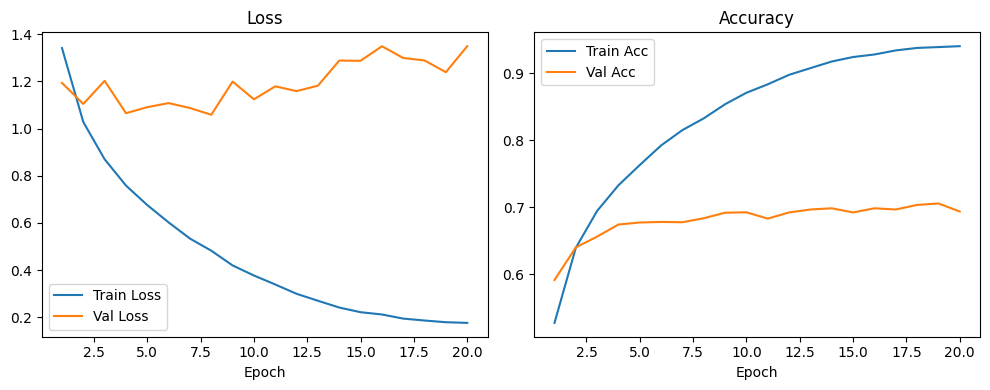

In [46]:
# Plot Loss & Accuracy curves
plot_history(final_history)

=== Final Fine-Tuned Model Classification Report ===
              precision    recall  f1-score   support

    Airplane      0.739     0.743     0.741      1000
  Automobile      0.810     0.771     0.790      1000
        Bird      0.624     0.640     0.632      1000
         Cat      0.532     0.546     0.539      1000
        Deer      0.661     0.633     0.647      1000
         Dog      0.651     0.600     0.625      1000
        Frog      0.738     0.798     0.767      1000
       Horse      0.752     0.693     0.721      1000
        Ship      0.756     0.754     0.755      1000
       Truck      0.717     0.797     0.755      1000

    accuracy                          0.698     10000
   macro avg      0.698     0.698     0.697     10000
weighted avg      0.698     0.698     0.697     10000



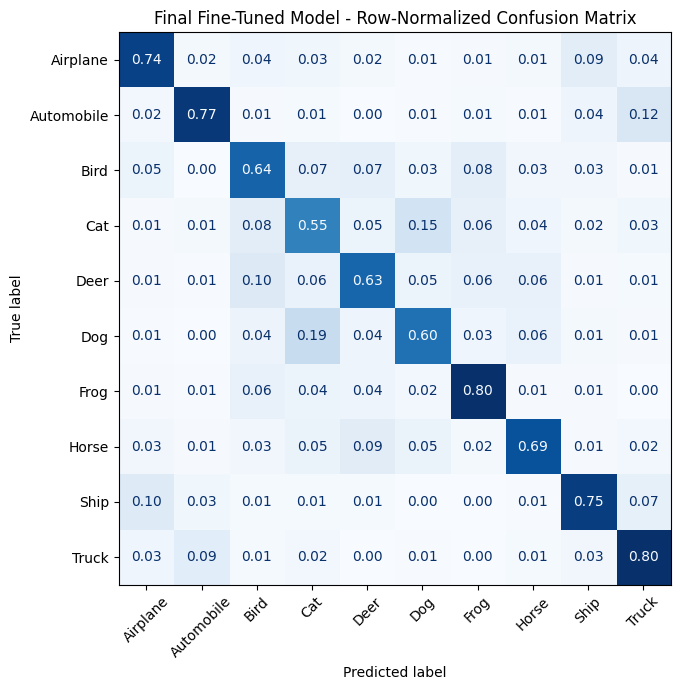

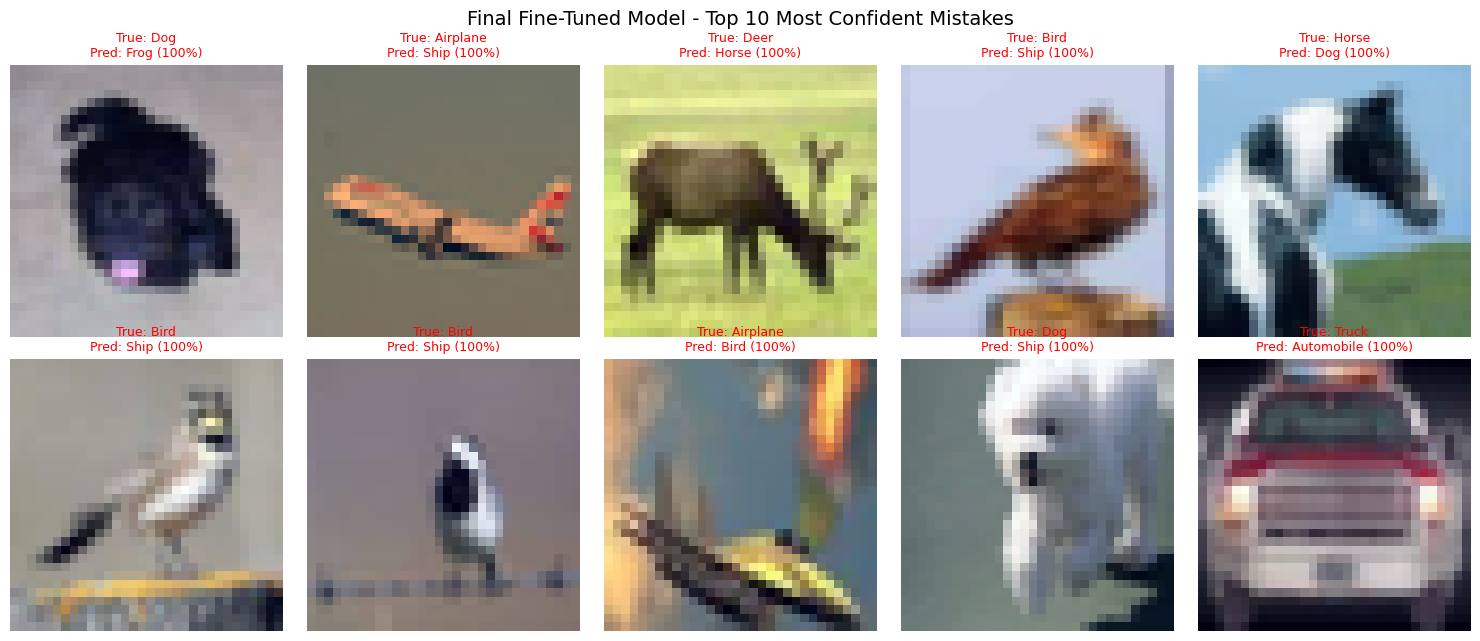

In [47]:
#@title Final Model Evaluation & Error Analysis

# 1. Collect test predictions using our evaluation helper
y_true, y_pred, probs = get_predictions(final_model, test_loader, device=DEVICE)

# 2. Display Classification Report, Confusion Matrix, and Top Mistakes
evaluate_and_visualize(
    y_true=y_true,
    y_pred=y_pred,
    probs=probs,
    dataset=test_dataset,
    class_names=CLASSES,
    title_prefix="Final Fine-Tuned Model"
)

**Reading the evaluation.**

- The **grey bars** (big data) are the reference: what this model achieves when data is plentiful.
- **All off → all on → tuned** shows how much of the gap to big data the toolbox closes. Where the confidence
  intervals don't overlap, the difference is real.
- Did the **tuned** model beat the hand-picked `all on`? Often by little or not at all on the test set — a search
  ranked on 50 validation images is noisy (§II.6). That's a finding, not a failure.
- The confusion matrix and the confident mistakes point at **what to do next**: which classes are confused,
  whether errors share a condition (small objects, clutter, unusual views), and whether some labels look wrong
  (Day 1's label audit). On small data, a handful of well-chosen new images often beats any further tuning.

---
## Summary

|  | Classifier Probe (Phase 1) | Stage 4 Fine-Tuning & Search (Phase 2) |
| --- | --- | --- |
| **What limits you** | **Bias** — frozen backbone features can't fully adapt | **Variance** — unfreezing risk of overfitting/oscillating loss |
| **Training loop** | Simple: forward pass, loss, backward, step | **Fast & Stable**: Mixed Precision (`amp`), Grad Clipping, Scheduler |
| **Linear probe vs fine-tune** | Quick baseline; trains head in 5 epochs | **Gradual unfreeze**: Stage 4 + Head fine-tuning wins on accuracy |
| **Model selection** | Basic validation loss and accuracy tracking | **W&B tracking**: evaluated via confusion matrix & top mistakes |
| **Hyperparameter search** | Fixed default learning rate ($10^{-3}$) | **7-Trial Random Search**: optimizes LR, decay, weight decay, smoothing |
| **The real fix** | Serves as a warm-start checkpoint for head | Proper learning rate scaling, regularization, & selective unfreezing |

---

## Checklist

* [x] **0** — GPU runtime, environment setup, and optional W&B tracking initialization
* [x] **I.1** — Pretrained ResNet-50 loaded and inspected (`named_children`, module structure, parameter counts)
* [x] **I.2** — Initial classifier layer replaced with `nn.Sequential(nn.Flatten(), nn.Linear(2048, 10))`
* [x] **I.3** — In-memory CIFAR-10 datasets wrapped in PyTorch `DataLoader` instances with normalization
* [x] **I.4** — Baseline training and evaluation functions implemented (`train_step`, `eval_step`, `fit`)
* [x] **I.5** — Classifier head trained on frozen backbone; training curves plotted
* [x] **I.6** — Backbone sub-modules inspected (`embedder`, stages) and Stage 4 selectively unfrozen
* [x] **II.1** — Upgraded training loop created with mixed precision (`torch.amp`) and gradient clipping (`max_norm`)
* [x] **II.2** — Warm-up classifier head trained for 5 epochs and base state saved as `warmed_classifier_base.pt`
* [x] **II.3** — Hyperparameter search executed (7 trials across LR, weight decay, label smoothing, LR decay)
* [x] **II.4** — Selected best hyperparameter config logged and stored
* [x] **II.5** — Final model fine-tuned for 20 epochs starting from the warmed-up checkpoint
* [x] **II.6** — Reusable evaluation suite built (`get_predictions`, `evaluate_and_visualize`)
* [x] **II.7** — Full performance analysis completed: Classification Report, Row-Normalized Confusion Matrix, and Top 10 Confident Mistakes

---

**Next:** Model Deployment — Quantization, ONNX export, or serving the fine-tuned model via API endpoints.

---
# References & Further Reading

### 🧭 Tutorials & guides
- **Hugging Face:** [Image classification fine-tuning](https://huggingface.co/docs/transformers/tasks/image_classification) · [`microsoft/resnet-50` model card](https://huggingface.co/microsoft/resnet-50) · [Image-classification models on the Hub](https://huggingface.co/models?pipeline_tag=image-classification) · [Auto classes](https://huggingface.co/docs/transformers/model_doc/auto)
- **PyTorch:** [Transfer learning for computer vision](https://pytorch.org/tutorials/beginner/transfer_learning_tutorial.html) · [Performance tuning guide](https://pytorch.org/tutorials/recipes/recipes/tuning_guide.html) · [AMP recipe](https://pytorch.org/tutorials/recipes/recipes/amp_recipe.html) · [AMP reference](https://pytorch.org/docs/stable/amp.html) · [`torch.utils.data`](https://pytorch.org/docs/stable/data.html) · [`clip_grad_norm_`](https://pytorch.org/docs/stable/generated/torch.nn.utils.clip_grad_norm_.html) · [TensorBoard with PyTorch](https://pytorch.org/tutorials/recipes/recipes/tensorboard_with_pytorch.html)
- **torchvision:** [Transforms v2](https://pytorch.org/vision/stable/transforms.html)
- **Weights & Biases:** [Sweeps](https://docs.wandb.ai/guides/sweeps/) · [wandb.ai](https://wandb.ai)
- **Data:** [fastai/imagenette (ImageNette & ImageWoof)](https://github.com/fastai/imagenette)

### 📄 Papers — *cited inline above*
1. **J. Yosinski, J. Clune, Y. Bengio, H. Lipson** — *How transferable are features in deep neural networks?*, NeurIPS 2014.
2. **J. Deng et al.** — *ImageNet: A Large-Scale Hierarchical Image Database*, CVPR 2009.
3. **J. Howard** — *Imagenette*, GitHub (fastai/imagenette), 2019.
4. **K. He, X. Zhang, S. Ren, J. Sun** — *Deep Residual Learning for Image Recognition*, CVPR 2016.
5. **S. Geman, E. Bienenstock, R. Doursat** — *Neural Networks and the Bias/Variance Dilemma*, Neural Computation 4(1), 1992.
6. **J. Howard & S. Ruder** — *Universal Language Model Fine-tuning for Text Classification* (gradual unfreezing, discriminative learning rates), ACL 2018.
7. **S. G. Müller & F. Hutter** — *TrivialAugment: Tuning-free Yet State-of-the-Art Data Augmentation*, ICCV 2021.
8. **Z. Zhong, L. Zheng, G. Kang, S. Li, Y. Yang** — *Random Erasing Data Augmentation*, AAAI 2020.
9. **I. Loshchilov & F. Hutter** — *Decoupled Weight Decay Regularization*, ICLR 2019.
10. **C. Szegedy, V. Vanhoucke, S. Ioffe, J. Shlens, Z. Wojna** — *Rethinking the Inception Architecture for Computer Vision* (label smoothing), CVPR 2016.
11. **R. Pascanu, T. Mikolov, Y. Bengio** — *On the difficulty of training recurrent neural networks* (gradient clipping), ICML 2013.
12. **P. Goyal et al.** — *Accurate, Large Minibatch SGD: Training ImageNet in 1 Hour* (learning-rate warm-up), arXiv:1706.02677, 2017.
13. **I. Loshchilov & F. Hutter** — *SGDR: Stochastic Gradient Descent with Warm Restarts* (cosine schedule), ICLR 2017.
14. **L. Prechelt** — *Early Stopping — But When?*, in *Neural Networks: Tricks of the Trade*, Springer, 1998.
15. **P. Micikevicius et al.** — *Mixed Precision Training*, ICLR 2018.
16. **J. Bergstra & Y. Bengio** — *Random Search for Hyper-Parameter Optimization*, JMLR 13, 2012.
17. **J. Snoek, H. Larochelle, R. P. Adams** — *Practical Bayesian Optimization of Machine Learning Algorithms*, NeurIPS 2012.
18. **L. Li, K. Jamieson, G. DeSalvo, A. Rostamizadeh, A. Talwalkar** — *Hyperband: A Novel Bandit-Based Approach to Hyperparameter Optimization*, JMLR 18, 2018.
19. **T. Wolf et al.** — *Transformers: State-of-the-Art Natural Language Processing*, EMNLP 2020 (System Demonstrations).
20. **L. Biewald** — *Experiment Tracking with Weights and Biases*, 2020. https://wandb.ai

Day 3 · Lab · Fine-tuning & advanced training · lab by **Anas Aldadi**.